<a href="https://colab.research.google.com/github/tasosquantumcomputing/Classification---Model-Selection-and-Evaluation/blob/main/Higgs_Boson_Signal_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Higgs Boson Signal Classification Using Machine Learning

## 1. Introduction

The discovery of the Higgs boson at CERN in 2012 represents one of the most important achievements in modern particle physics. The Higgs boson is associated with the Higgs field, which plays a fundamental role in the Standard Model of particle physics.

In high-energy particle collisions, many different physical processes can produce similar experimental signatures. Identifying events associated with Higgs boson production is therefore a challenging classification problem.

Machine Learning provides powerful computational tools for distinguishing potentially interesting physical events from background processes using measured or reconstructed properties of collision products.

The objective of this project is to investigate how different supervised Machine Learning algorithms perform in distinguishing Higgs-related signal events from background events.

---

## 2. Dataset Description

The **HIGGS Dataset**, available through the UCI Machine Learning Repository, was developed for research in Machine Learning applications to high-energy particle physics.

It contains simulated particle collision events representing two possible categories:

- **Signal (1):** Events associated with a simulated Higgs boson production and decay process.
- **Background (0):** Events produced by other physical processes that may resemble the signal.

The classification objective is to predict whether an event belongs to the signal or background category based on its physical characteristics.

### Dataset Characteristics

| Property | Description |
|---|---|
| Dataset | HIGGS |
| Scientific field | High-Energy Particle Physics |
| Original observations | 11,000,000 |
| Input features | 28 |
| Target classes | 2 |
| Learning task | Binary Classification |
| Data type | Numerical |
| Source | UCI Machine Learning Repository |

The dataset consists of Monte Carlo simulations rather than raw experimental observations.

### Physical Features

The dataset includes 28 numerical features divided into two categories.

**Low-Level Features (21)**

These quantities describe reconstructed physical properties of the particles and objects produced during collision events.

Examples include:

- Transverse momentum (\(p_T\))
- Pseudorapidity (\(\eta\))
- Azimuthal angle (\(\phi\))
- Missing transverse energy (\(E_T^{miss}\))
- Kinematic properties of reconstructed jets and leptons

These features contain information related to the dynamics and geometry of particle collision events.

**High-Level Features (7)**

These features are derived from combinations of lower-level quantities and are designed to capture additional information about the underlying physical processes.

Examples include:

- Invariant masses of reconstructed particle combinations
- Quantities associated with intermediate particle candidates
- Reconstructed mass-related observables

An important research question is whether Machine Learning algorithms can effectively exploit both low-level and high-level physical information to distinguish signal from background.

---

## 3. Project Objective

The main objective of this project is to develop, compare, and evaluate several supervised Machine Learning classifiers for Higgs signal identification.

Specifically, we aim to:

1. Explore the statistical properties of the dataset.
2. Investigate the distributions and correlations of physical features.
3. Prepare the data for Machine Learning algorithms.
4. Train and compare multiple classification models.
5. Evaluate predictive performance using cross-validation.
6. Optimize hyperparameters through systematic model selection.
7. Evaluate the selected model on previously unseen data.
8. Investigate classification errors and feature importance.

The project emphasizes both the computational methodology and the interpretation of results in the context of particle physics.

---

## 4. Dataset Selection and Sampling

The original HIGGS Dataset contains 11 million observations, making it computationally expensive for extensive experimentation with multiple Machine Learning algorithms.

For this educational project, we will use a smaller subset containing approximately **20,000 observations**.

This reduced dataset will allow us to perform model training, cross-validation, and hyperparameter optimization efficiently in Google Colab.

We will preserve both signal and background classes and inspect their relative frequencies before model development.

Sampling will be performed reproducibly using a fixed random seed, where possible.

The subset will be saved separately so that subsequent experiments can reuse the same observations without repeatedly downloading the original dataset.

Although the reduced dataset is more computationally manageable, its smaller size may limit the statistical precision and generalizability of our conclusions.

---

## 5. Machine Learning Models

We will investigate seven classification algorithms:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Gaussian Naive Bayes
4. Linear Support Vector Machine (SVM)
5. Radial Basis Function Support Vector Machine (RBF SVM)
6. Decision Tree
7. Random Forest

These models represent different approaches to classification, including linear decision boundaries, distance-based methods, probabilistic models, kernel methods, and tree-based learning.

Comparing them will help us investigate how model complexity and learning assumptions affect classification performance on simulated particle physics data.

---

## 6. Experimental Methodology

The project will follow a structured Machine Learning workflow.

### Exploratory Data Analysis

We will examine feature distributions, descriptive statistics, class frequencies, and relationships between physical variables.

### Data Preprocessing

The dataset will be divided into training and test sets using stratified sampling.

Feature scaling will be applied when required, using scikit-learn Pipelines to prevent data leakage.

### Model Training and Cross-Validation

The seven classifiers will be trained and evaluated using Stratified K-Fold Cross-Validation.

The primary evaluation metrics will include:

- Accuracy
- Precision
- Recall
- Macro F1-score

Because the scientific objective involves detecting signal events, we will also examine signal-class Recall and ROC-AUC where appropriate.

### Hyperparameter Optimization

GridSearchCV will be used to explore selected hyperparameters and identify promising configurations based on cross-validation performance.

### Final Model Evaluation

The selected classifier will be evaluated on an independent test set using:

- Test Accuracy
- Test Macro F1-score
- Confusion Matrix
- Classification Report
- Error Analysis

The test set will remain separate from model selection and hyperparameter optimization.

### Model Interpretation

Permutation Feature Importance will be used to investigate which physical variables contribute most strongly to the classifier's predictive performance.

We will also consider the limitations of feature-importance methods when input variables are strongly correlated.

---

## 7. Scientific Motivation

In experimental particle physics, identifying rare or interesting physical processes often requires distinguishing a signal from a large background of other events.

A classification algorithm must balance two competing objectives:

- **Signal Efficiency:** Correctly identifying genuine signal events.
- **Background Rejection:** Preventing background events from being incorrectly classified as signal.

This trade-off can be studied using Precision, Recall, confusion matrices, and ROC curves.

By investigating the performance of different algorithms, we aim to develop a better understanding of how Machine Learning can support data analysis in high-energy physics.

It is important to note that this project uses simulated and labeled events. Its conclusions therefore concern classification performance on the selected simulation dataset and do not constitute an experimental observation or discovery of the Higgs boson.

---

## 8. Expected Outcomes

By the end of this project, we expect to have:

- A reproducible data preprocessing and evaluation workflow.
- A comparative analysis of seven classification algorithms.
- Optimized hyperparameters for selected models.
- An independently evaluated final classifier.
- Visualizations of classification performance.
- An analysis of the most influential physical features.
- A documented Python notebook suitable for presentation in a GitHub portfolio.

The project will demonstrate the application of supervised Machine Learning techniques to a physically meaningful binary classification problem.

# Task 1 — HIGGS Dataset Loading and Subset Creation

## Objective

Load a reduced subset of the HIGGS dataset and prepare it for exploratory data analysis and machine learning.

The original dataset contains approximately 11 million simulated particle collision events. For this project, we will work with a subset of 20,000 observations to reduce computational requirements.

## Part 1 — Import Libraries

Import the following Python libraries:

- `pandas`
- `numpy`

## Part 2 — Load the Dataset

Use `pandas.read_csv()` to load observations from the HIGGS dataset hosted by the UCI Machine Learning Repository.

Dataset URL:

`https://mlphysics.ics.uci.edu/data/higgs/HIGGS.csv.gz`

Requirements:

- Specify the GZIP compression format.
- Specify that the dataset does not contain a header row.
- Read only the first 20,000 observations using `nrows=20000`.

Note that limiting the number of parsed rows does not guarantee a small network download when reading a remotely hosted compressed file.

## Part 3 — Inspect the Dataset

Display:

1. The dimensions of the dataset.
2. The first five observations.
3. The total number of columns.
4. The data types of the columns.

Expected dimensions:

- 20,000 observations
- 29 columns (1 target + 28 input features)

## Part 4 — Identify Features and Target

The first column represents the binary classification target:

- `1`: Higgs signal
- `0`: Background

The remaining 28 columns represent numerical physical features.

Separate the dataset into:

- `X`: Feature matrix
- `y`: Target vector

Display the shapes of both objects.

## Part 5 — Save the Reduced Dataset

Save the reduced dataset to a local CSV file named:

`higgs_subset_20000.csv`

The purpose is to reuse the same observations throughout the project without repeatedly accessing the original dataset.

For persistence across Google Colab sessions, save the file in Google Drive or another permanent location.

## Questions

1. Why does the dataset contain 29 columns but only 28 input features?
2. What type of machine learning problem are we solving?
3. What are the advantages and limitations of working with a reduced dataset?
4. Why should we save the selected subset before proceeding with model development?

## Expected Outcome

A reusable dataset containing 20,000 simulated particle physics events, ready for data inspection, exploratory analysis, and classification.

In [1]:
import numpy as np
import pandas as pd

In [4]:
url = "https://mlphysics.ics.uci.edu/data/higgs/HIGGS.csv.gz"

# Load the first 20,000 observations
df = pd.read_csv(
    url,
    compression="gzip",
    header=None,
    nrows=20000
)

# Display dataset dimensions
print("Dataset shape:", df.shape)

Dataset shape: (20000, 29)


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

# Create a project folder in Google Drive
folder = "/content/drive/MyDrive/Higgs_ML_Project"
os.makedirs(folder, exist_ok=True)

# Save the dataset
file_path = f"{folder}/higgs_subset_20000.csv"

df.to_csv(file_path, index=False, header=False)

print(f"Dataset saved successfully: {file_path}")

Dataset saved successfully: /content/drive/MyDrive/Higgs_ML_Project/higgs_subset_20000.csv


In [4]:
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Higgs_ML_Project/higgs_subset_20000.csv"

df = pd.read_csv(file_path, header=None)

print("Dataset shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (20000, 29)


### Dataset Storage and Reproducibility

A subset of 20,000 observations was extracted from the original HIGGS dataset.

To avoid repeatedly downloading the large source dataset, the subset was saved as a CSV file in Google Drive.

The stored dataset will be reused throughout the project, ensuring that all experiments are conducted on the same observations.

This approach improves computational efficiency and supports reproducibility.

# HIGGS Dataset — Feature Description and Physical Interpretation

## 1. Dataset Overview

The HIGGS dataset contains simulated high-energy particle collision events and is designed for binary classification of signal and background processes.

Each observation contains **29 columns**:

- **1 target variable**, indicating the event category.
- **21 low-level features**, describing reconstructed particle and jet kinematics.
- **7 high-level features**, representing derived physical quantities such as invariant masses.

The low-level features describe the properties of reconstructed objects, while the high-level features combine information from multiple objects to capture physically meaningful relationships.

## 2. Target Variable

| Feature | Description |
|---|---|
| `target` | Binary label identifying whether the event belongs to the signal or background category. |

**Target labels:**

- `1` — Signal: Simulated event associated with the Higgs-related signal process.
- `0` — Background: Simulated event associated with a competing physical process.

The machine learning objective is to predict the target label using the remaining 28 numerical features.

---

## 3. Low-Level Features

Low-level features represent kinematic properties and identification-related information associated with reconstructed collision products.

### 3.1 Lepton Features

| Feature | Physical Interpretation |
|---|---|
| `lepton_pt` | Transverse momentum of the reconstructed lepton, describing its momentum perpendicular to the beam axis. |
| `lepton_eta` | Pseudorapidity of the lepton, describing its direction relative to the beam axis. |
| `lepton_phi` | Azimuthal angle of the lepton's momentum in the plane perpendicular to the beam. |

**Transverse Momentum**

\[
p_T = \sqrt{p_x^2+p_y^2}
\]

The transverse momentum is especially important in particle collider experiments because the initial momentum perpendicular to the beam axis is approximately zero.

**Pseudorapidity**

\[
\eta = -\ln\left(\tan\frac{\theta}{2}\right)
\]

where \(\theta\) is the polar angle relative to the beam axis.

**Azimuthal Angle**

\[
\phi = \operatorname{atan2}(p_y,p_x)
\]

The azimuthal angle describes the orientation of a particle's momentum in the transverse plane.

### 3.2 Missing Transverse Energy

| Feature | Physical Interpretation |
|---|---|
| `missing_energy_magnitude` | Magnitude of the reconstructed missing transverse energy, associated with an imbalance in visible transverse momentum. |
| `missing_energy_phi` | Azimuthal direction of the missing transverse momentum vector. |

Missing transverse energy is an important observable in events involving particles that are not directly detected, such as neutrinos.

Ideally, momentum conservation in the transverse plane implies:

\[
\vec{p}_T^{\,miss} =
-\sum_i \vec{p}_{T,i}^{\,visible}
\]

Its magnitude is commonly denoted by \(E_T^{miss}\).

Large missing transverse energy may indicate invisible particles, although detector effects and reconstruction uncertainties can also contribute.

### 3.3 Jet 1 Features

| Feature | Physical Interpretation |
|---|---|
| `jet_1_pt` | Transverse momentum of the first reconstructed jet. |
| `jet_1_eta` | Pseudorapidity of the first jet. |
| `jet_1_phi` | Azimuthal angle of the first jet. |
| `jet_1_btag` | Numerical b-tagging information indicating how strongly the first jet is associated with a bottom quark. |

Jets are collimated sprays of particles produced through the hadronization of quarks and gluons.

A b-tagging variable provides information about whether a jet likely originated from a bottom quark.

### 3.4 Jet 2 Features

| Feature | Physical Interpretation |
|---|---|
| `jet_2_pt` | Transverse momentum of the second reconstructed jet. |
| `jet_2_eta` | Pseudorapidity of the second jet. |
| `jet_2_phi` | Azimuthal angle of the second jet. |
| `jet_2_btag` | B-tagging information for the second jet. |

### 3.5 Jet 3 Features

| Feature | Physical Interpretation |
|---|---|
| `jet_3_pt` | Transverse momentum of the third reconstructed jet. |
| `jet_3_eta` | Pseudorapidity of the third jet. |
| `jet_3_phi` | Azimuthal angle of the third jet. |
| `jet_3_btag` | B-tagging information for the third jet. |

### 3.6 Jet 4 Features

| Feature | Physical Interpretation |
|---|---|
| `jet_4_pt` | Transverse momentum of the fourth reconstructed jet. |
| `jet_4_eta` | Pseudorapidity of the fourth jet. |
| `jet_4_phi` | Azimuthal angle of the fourth jet. |
| `jet_4_btag` | B-tagging information for the fourth jet. |

The four reconstructed jets provide complementary information about the final-state particles.

Their momenta, directions, and b-tagging characteristics are potentially useful for distinguishing signal from background events.

---

## 4. High-Level Features

The final seven features are derived from combinations of low-level quantities.

These features were constructed using physical knowledge of the underlying collision processes.

### 4.1 Invariant Mass

The invariant mass of a system is defined by its total four-momentum.

Using natural units (\(c=1\)):

\[
m^2 = E^2-|\vec{p}|^2
\]

For a system containing multiple reconstructed objects:

\[
m^2 =
\left(\sum_i E_i\right)^2
-
\left|\sum_i \vec{p}_i\right|^2
\]

Invariant masses are useful because they can reveal structures associated with intermediate particles or resonance decays.

### 4.2 Derived Mass Features

| Feature | Physical Interpretation |
|---|---|
| `m_jj` | Invariant mass reconstructed from a selected pair of jets. |
| `m_jjj` | Invariant mass reconstructed from a selected combination of three jets. |
| `m_lv` | Reconstructed invariant mass of the lepton–neutrino system, associated with a leptonic W-boson candidate. |
| `m_jlv` | Reconstructed invariant mass combining a jet, a lepton, and a neutrino candidate. |
| `m_bb` | Invariant mass of a selected pair of b-tagged jet candidates. |
| `m_wbb` | Reconstructed invariant mass of a W-boson candidate combined with two b-jet candidates. |
| `m_wwbb` | Reconstructed invariant mass of a system containing two W-boson candidates and two b-jet candidates. |

These are reconstructed quantities. Their values depend on the object assignments and reconstruction procedures used in the simulation.

In particular, the `m_wwbb` feature is related to the reconstructed mass of the complete final-state system relevant to the studied Higgs signal process.

---

## 5. Low-Level vs High-Level Features

The dataset allows us to investigate the distinction between measured or reconstructed input features and physics-motivated derived features.

| Category | Features | Main Purpose |
|---|---:|---|
| Low-level | 21 | Describe individual reconstructed objects and their kinematics. |
| High-level | 7 | Capture relationships between reconstructed objects through derived physical observables. |

High-level features may contain useful information that is not immediately apparent when examining individual low-level features independently.

However, because they are derived from low-level quantities, they can also introduce correlations between input variables.

This makes the dataset especially interesting for studying the ability of different machine learning algorithms to exploit nonlinear relationships.

---

## 6. Important Considerations

### Feature Scaling and Units

The HIGGS dataset contains transformed numerical features.

Consequently, the stored values should not automatically be interpreted as raw physical measurements in units such as GeV or radians.

Feature distributions and preprocessing should be examined before model training.

### Correlated Features

Several variables may be statistically correlated due to their common physical origin or because high-level features are constructed from low-level quantities.

Correlation analysis will therefore be an important part of exploratory data analysis.

### Model Interpretation

A feature with high predictive importance is not necessarily the most fundamental physical quantity.

Feature importance describes how a particular trained model relies on the input data. It does not directly establish a causal physical relationship.

---

## 7. Project Relevance

Understanding the physical meaning of the dataset features is important for interpreting the results of machine learning classification.

Throughout the project, we will investigate:

1. Which physical observables differ most strongly between signal and background events.
2. Whether high-level features improve classification performance.
3. How correlations between physical quantities affect different machine learning algorithms.
4. Which variables contribute most strongly to the predictions of the selected model.
5. How classification performance relates to signal identification and background rejection.

This approach connects machine learning methodology with the physical interpretation of simulated high-energy particle collision events.

In [5]:
column_names = [
    "target",
    "lepton_pt",
    "lepton_eta",
    "lepton_phi",
    "missing_energy_magnitude",
    "missing_energy_phi",
    "jet_1_pt",
    "jet_1_eta",
    "jet_1_phi",
    "jet_1_btag",
    "jet_2_pt",
    "jet_2_eta",
    "jet_2_phi",
    "jet_2_btag",
    "jet_3_pt",
    "jet_3_eta",
    "jet_3_phi",
    "jet_3_btag",
    "jet_4_pt",
    "jet_4_eta",
    "jet_4_phi",
    "jet_4_btag",
    "m_jj",
    "m_jjj",
    "m_lv",
    "m_jlv",
    "m_bb",
    "m_wbb",
    "m_wwbb"
]

df.columns = column_names

display(df.head())

,target,lepton_pt,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet_1_pt,jet_1_eta,jet_1_phi,jet_1_btag,...,jet_4_eta,jet_4_phi,jet_4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,1.0,0.869293,-0.635082,0.225690,0.327470,-0.689993,0.754202,-0.248573,-1.092064,0.000000,...,-0.010455,-0.045767,3.101961,1.353760,0.979563,0.978076,0.920005,0.721657,0.988751,0.876678
1,1.0,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
2,1.0,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
3,0.0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
4,1.0,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487


In [6]:
df.keys()

Index(['target', 'lepton_pt', 'lepton_eta', 'lepton_phi',
       'missing_energy_magnitude', 'missing_energy_phi', 'jet_1_pt',
       'jet_1_eta', 'jet_1_phi', 'jet_1_btag', 'jet_2_pt', 'jet_2_eta',
       'jet_2_phi', 'jet_2_btag', 'jet_3_pt', 'jet_3_eta', 'jet_3_phi',
       'jet_3_btag', 'jet_4_pt', 'jet_4_eta', 'jet_4_phi', 'jet_4_btag',
       'm_jj', 'm_jjj', 'm_lv', 'm_jlv', 'm_bb', 'm_wbb', 'm_wwbb'],
      dtype='object')

In [7]:
df.head()

,target,lepton_pt,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet_1_pt,jet_1_eta,jet_1_phi,jet_1_btag,...,jet_4_eta,jet_4_phi,jet_4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,1.0,0.869293,-0.635082,0.225690,0.327470,-0.689993,0.754202,-0.248573,-1.092064,0.000000,...,-0.010455,-0.045767,3.101961,1.353760,0.979563,0.978076,0.920005,0.721657,0.988751,0.876678
1,1.0,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
2,1.0,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
3,0.0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
4,1.0,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487


In [8]:
df["class_name"] = df["target"].map({
    0: "Background",
    1: "Higgs Signal"
})

In [9]:
df.head()

,target,lepton_pt,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet_1_pt,jet_1_eta,jet_1_phi,jet_1_btag,...,jet_4_phi,jet_4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb,class_name
0,1.0,0.869293,-0.635082,0.225690,0.327470,-0.689993,0.754202,-0.248573,-1.092064,0.000000,...,-0.045767,3.101961,1.353760,0.979563,0.978076,0.920005,0.721657,0.988751,0.876678,Higgs Signal
1,1.0,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343,Higgs Signal
2,1.0,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118,Higgs Signal
3,0.0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904,Background
4,1.0,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487,Higgs Signal


In [10]:
df.keys()

Index(['target', 'lepton_pt', 'lepton_eta', 'lepton_phi',
       'missing_energy_magnitude', 'missing_energy_phi', 'jet_1_pt',
       'jet_1_eta', 'jet_1_phi', 'jet_1_btag', 'jet_2_pt', 'jet_2_eta',
       'jet_2_phi', 'jet_2_btag', 'jet_3_pt', 'jet_3_eta', 'jet_3_phi',
       'jet_3_btag', 'jet_4_pt', 'jet_4_eta', 'jet_4_phi', 'jet_4_btag',
       'm_jj', 'm_jjj', 'm_lv', 'm_jlv', 'm_bb', 'm_wbb', 'm_wwbb',
       'class_name'],
      dtype='object')

In [11]:
df.shape

(20000, 30)

In [12]:
df.size

600000

In [13]:
df.shape[0]

20000

In [14]:
df.shape[1]

30

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   target                    20000 non-null  float64
 1   lepton_pt                 20000 non-null  float64
 2   lepton_eta                20000 non-null  float64
 3   lepton_phi                20000 non-null  float64
 4   missing_energy_magnitude  20000 non-null  float64
 5   missing_energy_phi        20000 non-null  float64
 6   jet_1_pt                  20000 non-null  float64
 7   jet_1_eta                 20000 non-null  float64
 8   jet_1_phi                 20000 non-null  float64
 9   jet_1_btag                20000 non-null  float64
 10  jet_2_pt                  20000 non-null  float64
 11  jet_2_eta                 20000 non-null  float64
 12  jet_2_phi                 20000 non-null  float64
 13  jet_2_btag                20000 non-null  float64
 14  jet_3_

In [16]:
df.dtypes

,0
target,float64
lepton_pt,float64
lepton_eta,float64
lepton_phi,float64
missing_energy_magnitude,float64
missing_energy_phi,float64
jet_1_pt,float64
jet_1_eta,float64
jet_1_phi,float64
jet_1_btag,float64


In [17]:
missing_values = df.isnull()
print(missing_values)

       target  lepton_pt  lepton_eta  lepton_phi  missing_energy_magnitude  \
0       False      False       False       False                     False   
1       False      False       False       False                     False   
2       False      False       False       False                     False   
3       False      False       False       False                     False   
4       False      False       False       False                     False   
...       ...        ...         ...         ...                       ...   
19995   False      False       False       False                     False   
19996   False      False       False       False                     False   
19997   False      False       False       False                     False   
19998   False      False       False       False                     False   
19999   False      False       False       False                     False   

       missing_energy_phi  jet_1_pt  jet_1_eta  jet_1_phi  jet_

In [18]:
df.isnull().sum()

,0
target,0
lepton_pt,0
lepton_eta,0
lepton_phi,0
missing_energy_magnitude,0
missing_energy_phi,0
jet_1_pt,0
jet_1_eta,0
jet_1_phi,0
jet_1_btag,0


In [19]:
df.duplicated().sum()

np.int64(1)

In [20]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
19995,False
19996,False
19997,False
19998,False


In [21]:
df.describe()

,target,lepton_pt,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet_1_pt,jet_1_eta,jet_1_phi,jet_1_btag,...,jet_4_eta,jet_4_phi,jet_4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
count,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,0.52285,0.995558,-0.008945,0.003526,0.992783,-0.007648,0.989585,-0.005452,-0.001949,0.997279,...,-0.001004,-0.004967,0.996660,1.036581,1.024865,1.050357,1.012662,0.972479,1.033339,0.958947
std,0.49949,0.574273,1.005109,1.006659,0.596565,1.005870,0.472263,1.012621,1.013607,1.026503,...,1.008236,1.005074,1.395198,0.660935,0.375650,0.163363,0.399096,0.528967,0.364430,0.311010
min,0.00000,0.274880,-2.434976,-1.742508,0.003158,-1.743755,0.159488,-2.960813,-1.741237,0.000000,...,-2.496432,-1.742691,0.000000,0.146606,0.342015,0.266788,0.384411,0.080986,0.388779,0.441184
25%,0.00000,0.594780,-0.742218,-0.865827,0.570723,-0.882153,0.680527,-0.703089,-0.884866,0.000000,...,-0.715023,-0.876473,0.000000,0.791883,0.846700,0.985779,0.769800,0.672339,0.821102,0.770364
50%,1.00000,0.856483,-0.016612,0.015120,0.885347,-0.014749,0.897155,-0.002501,0.005427,1.086538,...,0.001205,-0.006923,0.000000,0.896459,0.950655,0.989801,0.918998,0.870757,0.946824,0.870945
75%,1.00000,1.239521,0.724579,0.878207,1.295151,0.861134,1.167442,0.692145,0.871085,2.173076,...,0.718266,0.858426,3.101961,1.028629,1.084157,1.020328,1.145256,1.132294,1.136419,1.059801
max,1.00000,7.000281,2.429998,1.743236,6.582300,1.743052,7.064657,2.969674,1.741454,2.173076,...,2.495511,1.742817,3.101961,16.131908,8.940148,3.682260,6.583121,8.255083,6.401313,4.535003


In [22]:
X = df.drop(columns=['target', 'class_name'])
y = df['target']

## Task 2 — Target Distribution and Class Balance

### Objective

Investigate the distribution of the target variable in the HIGGS dataset and determine whether the two event classes are balanced.

Understanding the class distribution is an important step before model training, since class imbalance can influence classification performance and the interpretation of evaluation metrics.

### Background

The dataset contains two classes:

- **Class 0 — Background:** Events originating from background physical processes.
- **Class 1 — Higgs Signal:** Events associated with the simulated Higgs signal process.

In particle physics, distinguishing signal from background is a fundamental classification problem.

The relative frequency of each class can affect how a machine learning algorithm learns to identify signal events.

### Part 1 — Class Distribution

Using the target variable `y`:

1. Calculate the number of observations belonging to each class.
2. Calculate the percentage of observations in each class.
3. Display the results in a readable format.

### Part 2 — Data Visualization

Create a bar chart showing the distribution of the two target classes.

Requirements:

- Use `matplotlib` or `seaborn`.
- Display the class names: `Background` and `Higgs Signal`.
- Label the horizontal and vertical axes.
- Add an appropriate chart title.
- Display the number of observations above each bar.

### Part 3 — Class Balance Analysis

Examine the class distribution and answer the following questions:

1. How many background events are included in the dataset?
2. How many Higgs signal events are included?
3. What percentage of the dataset belongs to each class?
4. Is the dataset balanced or imbalanced?
5. Why can class imbalance be problematic in binary classification?

### Part 4 — Physical Interpretation

Consider the importance of class distribution in high-energy particle physics.

In realistic particle physics experiments, potentially interesting signal processes may occur much less frequently than background processes.

Discuss why a classifier with high overall accuracy may still be unsuitable for signal identification if it fails to detect a significant proportion of actual signal events.

### Expected Outcome

By completing this task, we should have:

- A numerical summary of the target distribution.
- A bar chart illustrating the frequency of signal and background events.
- An understanding of class balance in the selected dataset.
- An initial discussion of why Precision, Recall, and F1-score are important for particle physics classification problems.

**Important:** This task involves only exploratory analysis. Do not split the dataset, scale features, or train machine learning models yet.

In [23]:
y.value_counts()

,count
target,
1.0,10457
0.0,9543


In [24]:
prec_0 = y.value_counts()[0]/len(y)
prec_1 = y.value_counts()[1]/len(y)
print(f"Percentage of class 0: {prec_0}")
print(f"Percentage of class 1: {prec_1}")

Percentage of class 0: 0.47715
Percentage of class 1: 0.52285


In [25]:
dic = {"background signal":prec_0*100, "higgs signal":prec_1*100}

In [26]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Class Distribution')

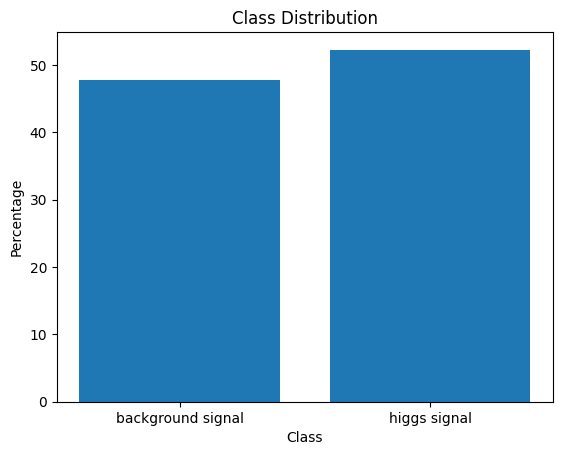

In [27]:
fig, ax = plt.subplots()
ax.bar(dic.keys(), dic.values())
ax.set_xlabel("Class")
ax.set_ylabel("Percentage")
ax.set_title("Class Distribution")

### Class Distribution Analysis

The selected HIGGS dataset subset contains 20,000 simulated particle collision events.

The class distribution is:

- **Background (Class 0):** 9,543 events (47.72%)
- **Higgs Signal (Class 1):** 10,457 events (52.28%)

The two classes are approximately balanced, with a slight predominance of signal events.

This distribution provides a suitable starting point for comparing different binary classification algorithms without severe class imbalance.

However, overall accuracy alone may not fully describe classification performance. In the context of particle physics, signal detection efficiency and background rejection are also important considerations.

Therefore, additional evaluation metrics such as Precision, Recall, F1-score, and ROC-AUC will be considered during model evaluation.

It is important to note that the class proportions in this simulated subset do not necessarily represent the relative frequencies of signal and background events in real collider experiments.

## Task 2 — Part 3: Class Balance Analysis

### 1. Is the dataset balanced or imbalanced?

The dataset is approximately balanced.

The class distribution is:

- **Background:** 9,543 events (47.72%)
- **Higgs Signal:** 10,457 events (52.28%)

The difference between the two classes is relatively small, approximately 4.57 percentage points.

Therefore, there is no severe class imbalance that would require immediate corrective measures such as oversampling or class weighting.

### 2. What would happen if 99% of the observations belonged to the background class and only 1% to the signal class?

Such a dataset would be highly imbalanced.

A machine learning algorithm could become biased toward predicting the majority class (Background), since background events dominate the training data.

As a result, the classifier might perform well on background events while failing to identify the rare signal events.

This would be particularly problematic in particle physics, where detecting rare physical processes is often the primary scientific objective.

### 3. Could a classifier achieve 99% accuracy without detecting any Higgs signal events?

Yes.

Suppose a dataset contains:

- 99,000 background events.
- 1,000 Higgs signal events.

A classifier that predicts every observation as Background would correctly classify 99,000 out of 100,000 events.

Its accuracy would be:

\[
Accuracy = \frac{99000}{100000}=0.99
\]

Therefore, it would achieve **99% accuracy**, despite failing to identify a single Higgs signal event.

Its signal Recall would be:

\[
Recall_{signal}=\frac{TP}{TP+FN}=0
\]

This demonstrates why accuracy alone can be misleading when dealing with highly imbalanced datasets.

### 4. Why might Recall be particularly important when identifying rare signal events?

Recall measures the proportion of actual signal events correctly identified by the classifier.

\[
Recall_{signal}=\frac{TP}{TP+FN}
\]

In particle physics, signal Recall is closely related to **signal efficiency**.

A low Recall indicates that the classifier misses a significant fraction of genuine signal events.

When studying rare physical processes, missing signal events can reduce the amount of useful information available for subsequent analysis.

Therefore, achieving sufficiently high signal efficiency is an important objective.

However, maximizing Recall alone is not enough, since a classifier could label almost every event as signal and generate excessive false positives.

### 5. Why should we consider both signal efficiency and background rejection?

An effective particle physics classifier should correctly identify signal events while rejecting as many background events as possible.

**Signal Efficiency:**

\[
\epsilon_S=\frac{TP}{TP+FN}
\]

**Background Rejection Fraction:**

\[
R_B=\frac{TN}{TN+FP}
\]

High signal efficiency ensures that a large proportion of genuine signal events is retained.

High background rejection ensures that relatively few background events are incorrectly identified as signal.

These objectives often involve a trade-off.

For example, lowering the classification threshold may increase signal efficiency but also increase the number of background events incorrectly classified as signal.

The optimal balance depends on the scientific objective and the relative costs of false positives and false negatives.

Metrics such as ROC-AUC and ROC curves can help investigate this trade-off.

---

### Conclusion

The selected HIGGS dataset subset is approximately balanced, making it suitable for initial comparisons between machine learning classifiers.

Nevertheless, evaluating classification performance requires more than overall accuracy.

In particle physics applications, **signal efficiency, background rejection, Precision, Recall, and F1-score** provide complementary information about the ability of a classifier to distinguish interesting physical events from background processes.

These metrics will be considered during the subsequent model evaluation tasks.

## Task 2 — Part 4: Physical Interpretation

### Signal and Background Classification in High-Energy Physics

In high-energy particle physics, the identification of rare physical processes is one of the main challenges in experimental data analysis.

Particle collisions can produce a wide variety of final states, and different physical processes may generate similar experimental signatures.

Consequently, distinguishing events associated with a signal process from those originating from background processes is an important application of Machine Learning.

### Signal Efficiency

Signal efficiency measures the fraction of genuine signal events correctly identified by a classifier.

\[
\epsilon_S = \frac{TP}{TP+FN}
\]

where:

- **TP (True Positives):** Signal events correctly classified as signal.
- **FN (False Negatives):** Signal events incorrectly classified as background.

A high signal efficiency is desirable because it allows researchers to retain a large fraction of potentially interesting events.

### Background Rejection

Background rejection can be expressed as the fraction of background events correctly rejected:

\[
R_B = \frac{TN}{TN+FP}
\]

where:

- **TN (True Negatives):** Background events correctly classified as background.
- **FP (False Positives):** Background events incorrectly classified as signal.

A high background rejection fraction reduces the contamination of selected signal candidates by background processes.

In particle physics literature, background rejection is also commonly expressed as the inverse background efficiency:

\[
\frac{1}{\epsilon_B},
\qquad
\epsilon_B = \frac{FP}{FP+TN}
\]

These two definitions represent different quantities and should not be confused.

### Trade-Off Between Signal Efficiency and Background Rejection

A classification model typically assigns a score or probability-like value indicating how strongly an event resembles the signal class.

By adjusting the classification threshold, we can control the trade-off between signal efficiency and background rejection.

A lower threshold generally increases signal efficiency but also allows more background events to be incorrectly selected as signal.

A higher threshold generally improves background rejection at the expense of losing some genuine signal events.

Therefore, selecting an appropriate threshold depends on the scientific objectives of the analysis.

### Importance of Class Imbalance

In realistic particle physics experiments, background processes may occur much more frequently than the signal process of interest.

This creates a challenge for machine learning classifiers because a model may achieve high overall accuracy while failing to identify rare signal events.

For this reason, classification accuracy should not be the only evaluation metric.

Signal Recall, Precision, F1-score, ROC curves, and background efficiency provide additional information about the classifier's ability to distinguish signal from background.

Furthermore, the class proportions in our approximately balanced simulated dataset do not necessarily represent the true signal-to-background ratio encountered in an experiment.

### Connection to the HIGGS Dataset

The HIGGS dataset contains simulated collision events described by 28 numerical features, including reconstructed particle kinematics and derived invariant masses.

Machine Learning classifiers will attempt to identify statistical patterns in these physical observables that distinguish Higgs-related signal events from background events.

Our project will investigate which classification algorithms can achieve strong predictive performance and how effectively they balance signal identification with background rejection.

### Conclusion

The evaluation of machine learning models in high-energy physics requires considering both statistical classification performance and the physical objectives of the analysis.

An effective classifier should retain a high fraction of genuine signal events while minimizing background contamination.

Throughout this project, we will evaluate model performance using multiple complementary metrics and investigate the relationship between predictive accuracy, signal efficiency, and background rejection.

# Task 3 — Exploratory Data Analysis (EDA)

## Objective

Perform an exploratory analysis of the HIGGS dataset to understand the statistical properties, distributions, and physical characteristics of the input variables.

The primary objective is to investigate whether the numerical features exhibit different statistical behavior for **Higgs Signal** and **Background** events.

This analysis will help us understand the dataset before applying machine learning classification algorithms.

---

## Part 1 — Descriptive Statistics

Using the DataFrame `X`, perform the following:

1. Calculate descriptive statistics for all 28 numerical features using `describe()`.
2. Examine the mean, standard deviation, minimum, maximum, and quartiles.
3. Identify features with particularly large ranges or high variability.
4. Check whether different features operate on significantly different numerical scales.

### Questions

1. Which features exhibit the highest standard deviations?
2. Do all features have approximately the same numerical scale?
3. Why might differences in feature scaling affect certain machine learning algorithms?

---

## Part 2 — Feature Distributions

Investigate the distributions of selected physical features.

Focus on the following variables:

- `lepton_pt`
- `lepton_eta`
- `missing_energy_magnitude`
- `jet_1_pt`
- `jet_1_btag`
- `m_bb`
- `m_wwbb`

### Instructions

1. Create histograms for the selected features.
2. Use appropriate axis labels and titles.
3. Examine the shape of each distribution.
4. Identify skewness, long tails, and potential extreme values.
5. Compare the numerical ranges of different features.

### Questions

1. Which features appear approximately symmetric?
2. Which features exhibit strongly skewed distributions?
3. Are there any features with unusually large values?
4. How might the physical interpretation of each variable explain its distribution?

---

## Part 3 — Signal vs Background Distributions

Investigate whether individual physical observables can help distinguish Higgs Signal from Background.

### Instructions

For the following features:

- `lepton_pt`
- `missing_energy_magnitude`
- `jet_1_pt`
- `m_bb`
- `m_wwbb`

Create overlapping histograms or density plots comparing:

- Background events (`target = 0`)
- Higgs Signal events (`target = 1`)

### Visualization Requirements

1. Use different colors for Signal and Background.
2. Include a legend identifying both classes.
3. Label each axis appropriately.
4. Add descriptive titles.
5. Use normalized histograms (`stat="density"` or `density=True`) to compare distribution shapes rather than raw event counts.

### Questions

1. Which features show noticeable differences between Signal and Background?
2. Which features exhibit substantial overlap between the two classes?
3. Can a single physical feature reliably distinguish Signal from Background?
4. Why might combining multiple physical observables improve classification performance?

---

## Part 4 — Boxplots by Event Class

Create boxplots to compare the distributions of selected features across the two event classes.

Use:

- `lepton_pt`
- `jet_1_pt`
- `missing_energy_magnitude`
- `m_bb`
- `m_wwbb`

### Instructions

1. Create a separate boxplot for each feature.
2. Use `class_name` to distinguish Signal from Background.
3. Compare medians, interquartile ranges, and potential outliers.
4. Discuss differences in the distributions between the two classes.

### Questions

1. Which features exhibit the largest differences in median values?
2. Which features show significant variability?
3. Do the distributions contain potential outliers?
4. Why should extreme values not automatically be removed from particle physics datasets?

---

## Part 5 — Physical Interpretation

Based on the exploratory analysis, discuss the physical meaning of the observed patterns.

Consider the following questions:

1. Why might the transverse momentum distributions differ between Signal and Background events?
2. How can missing transverse energy provide information about invisible particles such as neutrinos?
3. Why might reconstructed invariant masses be particularly useful for identifying Higgs-related processes?
4. What is the significance of substantial overlap between Signal and Background feature distributions?
5. Why might nonlinear machine learning algorithms be useful for analyzing complex relationships between physical observables?

---

## Expected Outcome

By completing this task, we should obtain:

- A statistical summary of the 28 input features.
- Histograms showing the distributions of selected physical observables.
- Comparative visualizations of Signal and Background events.
- Boxplots highlighting differences in feature distributions.
- An initial physical interpretation of potentially discriminative variables.

The exploratory analysis will provide a foundation for subsequent feature correlation analysis, preprocessing, model training, and classification.

**Important:** Do not train machine learning models, perform feature scaling, or modify the original dataset during this task.

In [28]:
X.describe()

,lepton_pt,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet_1_pt,jet_1_eta,jet_1_phi,jet_1_btag,jet_2_pt,...,jet_4_eta,jet_4_phi,jet_4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,0.995558,-0.008945,0.003526,0.992783,-0.007648,0.989585,-0.005452,-0.001949,0.997279,0.987809,...,-0.001004,-0.004967,0.996660,1.036581,1.024865,1.050357,1.012662,0.972479,1.033339,0.958947
std,0.574273,1.005109,1.006659,0.596565,1.005870,0.472263,1.012621,1.013607,1.026503,0.492486,...,1.008236,1.005074,1.395198,0.660935,0.375650,0.163363,0.399096,0.528967,0.364430,0.311010
min,0.274880,-2.434976,-1.742508,0.003158,-1.743755,0.159488,-2.960813,-1.741237,0.000000,0.188981,...,-2.496432,-1.742691,0.000000,0.146606,0.342015,0.266788,0.384411,0.080986,0.388779,0.441184
25%,0.594780,-0.742218,-0.865827,0.570723,-0.882153,0.680527,-0.703089,-0.884866,0.000000,0.656178,...,-0.715023,-0.876473,0.000000,0.791883,0.846700,0.985779,0.769800,0.672339,0.821102,0.770364
50%,0.856483,-0.016612,0.015120,0.885347,-0.014749,0.897155,-0.002501,0.005427,1.086538,0.886990,...,0.001205,-0.006923,0.000000,0.896459,0.950655,0.989801,0.918998,0.870757,0.946824,0.870945
75%,1.239521,0.724579,0.878207,1.295151,0.861134,1.167442,0.692145,0.871085,2.173076,1.200868,...,0.718266,0.858426,3.101961,1.028629,1.084157,1.020328,1.145256,1.132294,1.136419,1.059801
max,7.000281,2.429998,1.743236,6.582300,1.743052,7.064657,2.969674,1.741454,2.173076,7.627234,...,2.495511,1.742817,3.101961,16.131908,8.940148,3.682260,6.583121,8.255083,6.401313,4.535003


In [29]:
features = [
    "lepton_pt",
    "lepton_eta",
    "missing_energy_magnitude",
    "jet_1_pt",
    "jet_1_btag",
    "m_bb",
    "m_wwbb"
]

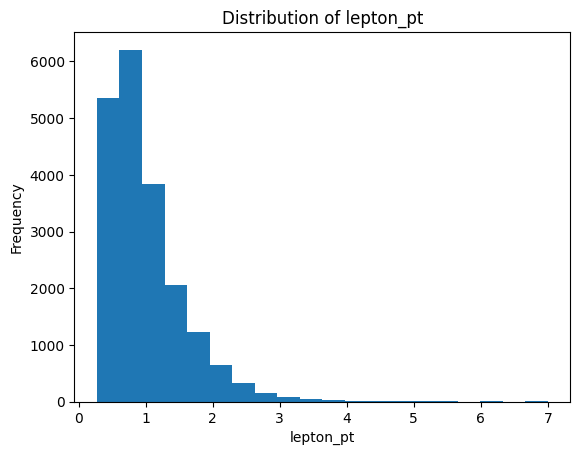

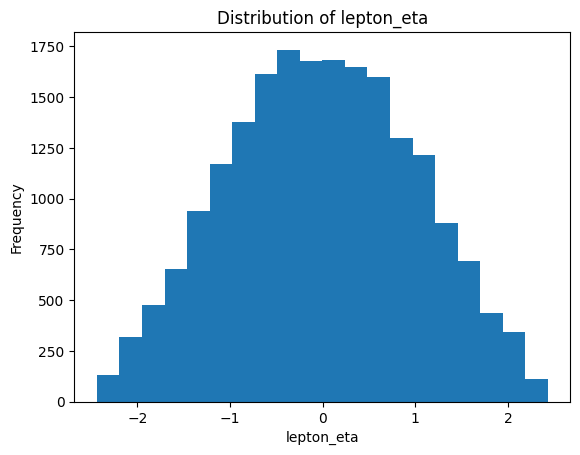

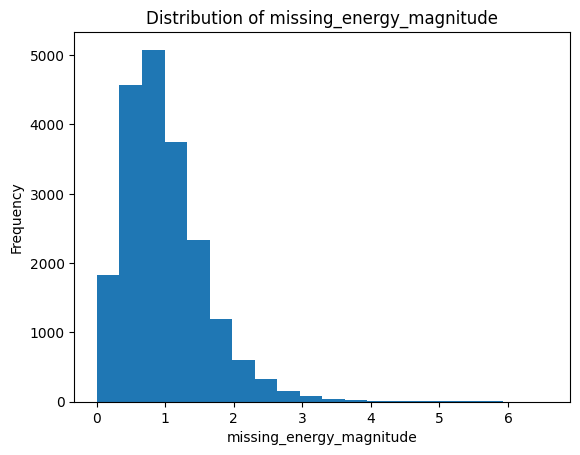

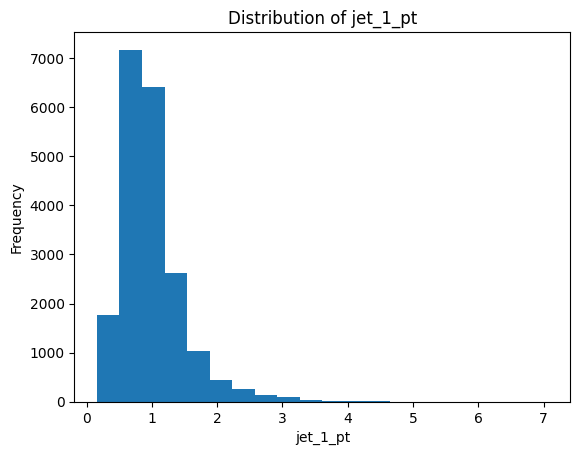

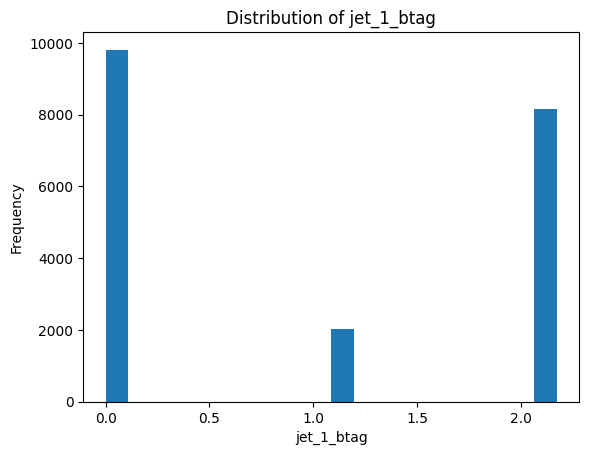

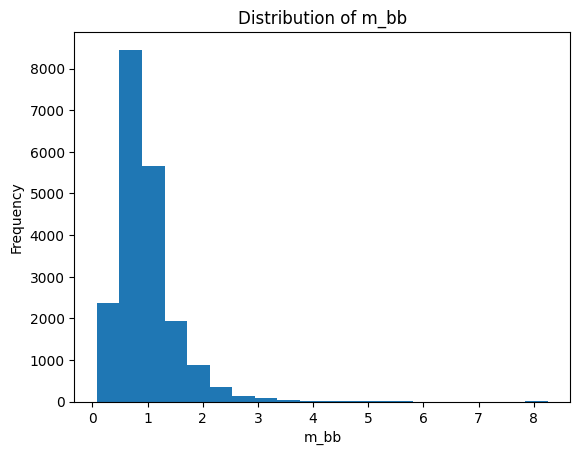

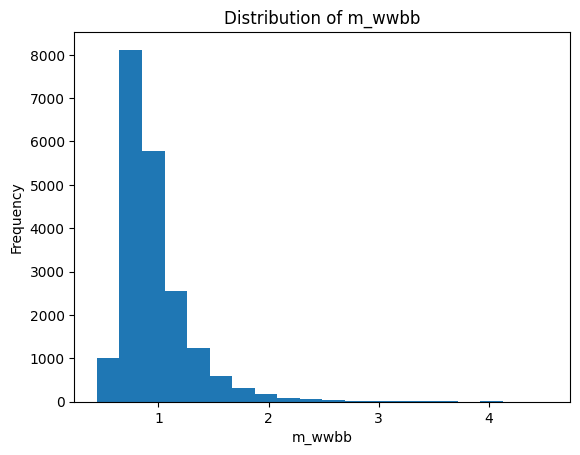

In [33]:
for i in features:
  plt.hist(X[i],bins = 20)
  plt.xlabel(i)
  plt.ylabel("Frequency")
  plt.title(f"Distribution of {i}")
  plt.show()

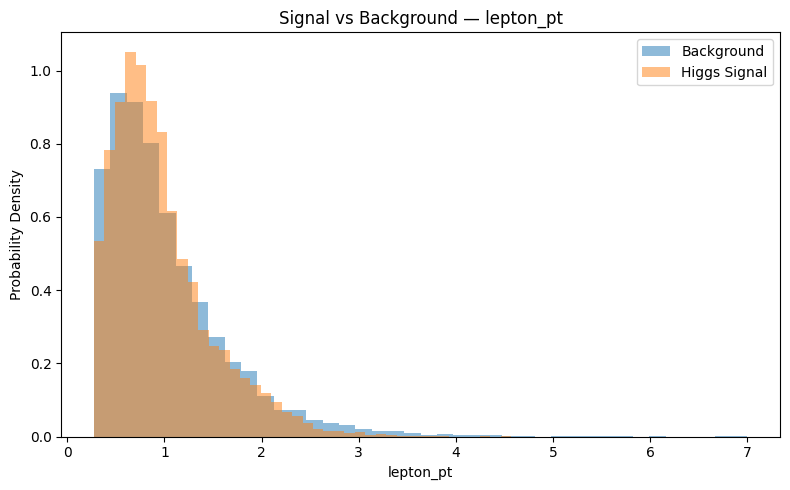

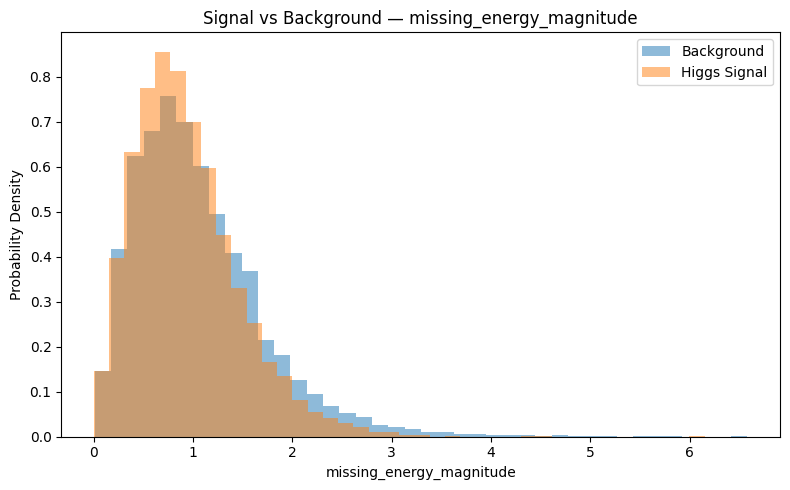

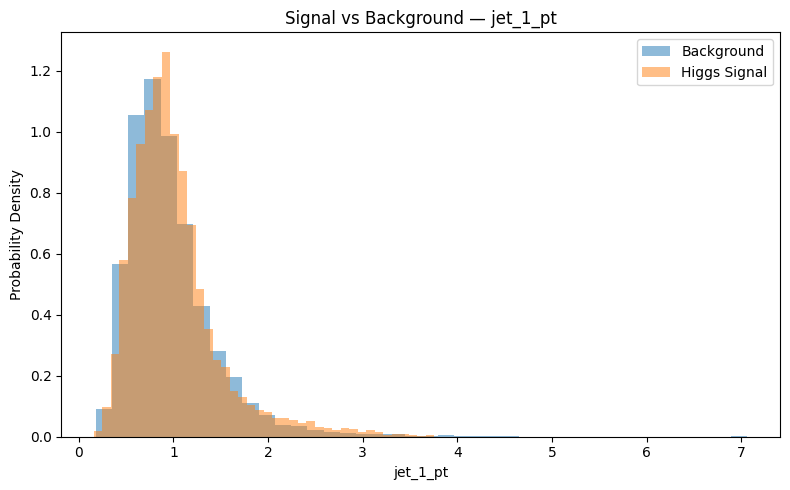

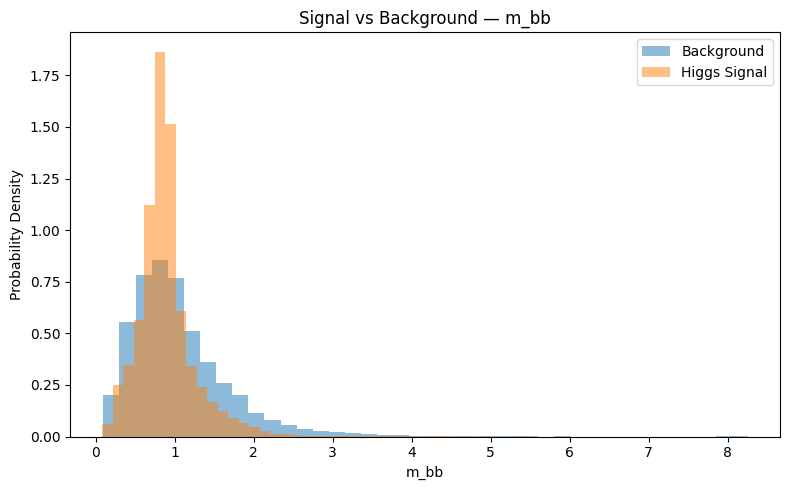

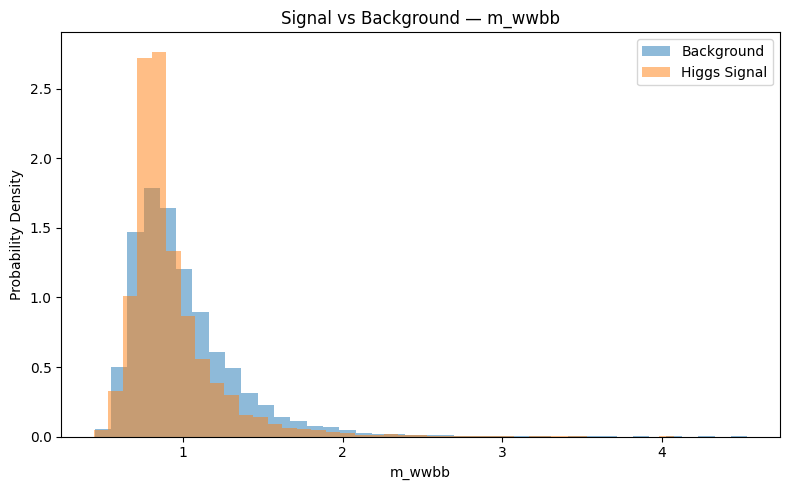

In [37]:
features = [
    "lepton_pt",
    "missing_energy_magnitude",
    "jet_1_pt",
    "m_bb",
    "m_wwbb"
]

for feature in features:

    plt.figure(figsize=(8, 5))

    plt.hist(
        df[df["target"] == 0][feature],
        bins=40,
        density=True,
        alpha=0.5,
        label="Background"
    )

    plt.hist(
        df[df["target"] == 1][feature],
        bins=40,
        density=True,
        alpha=0.5,
        label="Higgs Signal"
    )

    plt.xlabel(feature)
    plt.ylabel("Probability Density")
    plt.title(f"Signal vs Background — {feature}")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [38]:
features_box = ['lepton_pt','jet_1_pt','missing_energy_magnitude','m_bb','m_wwbb']

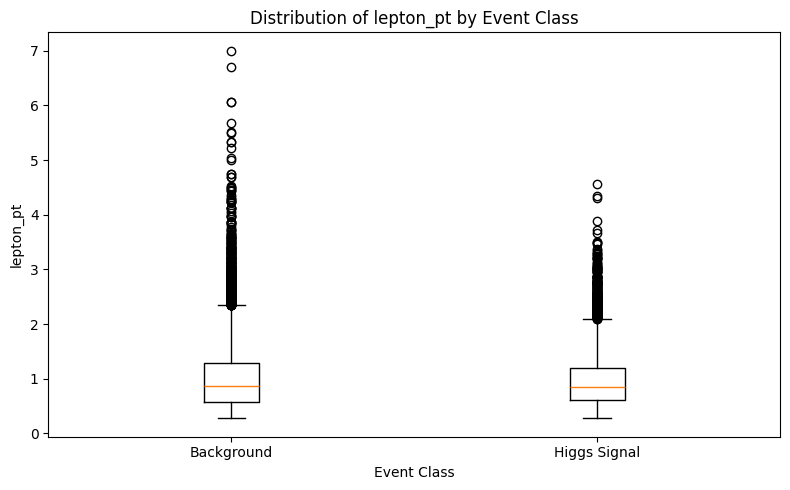

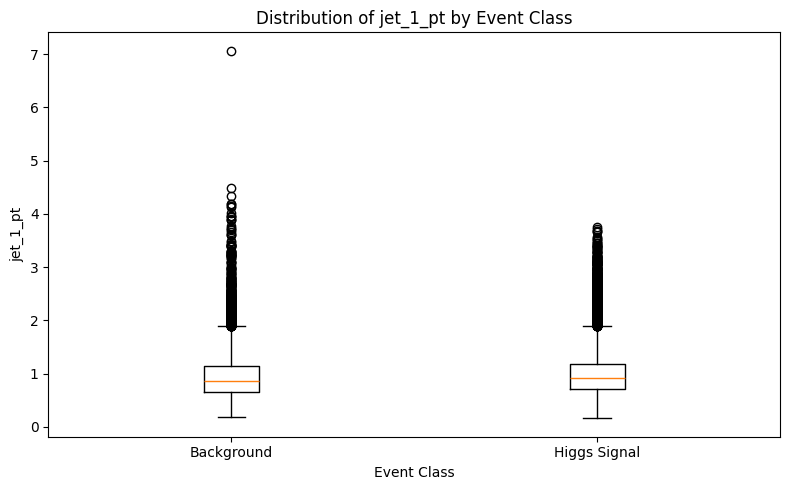

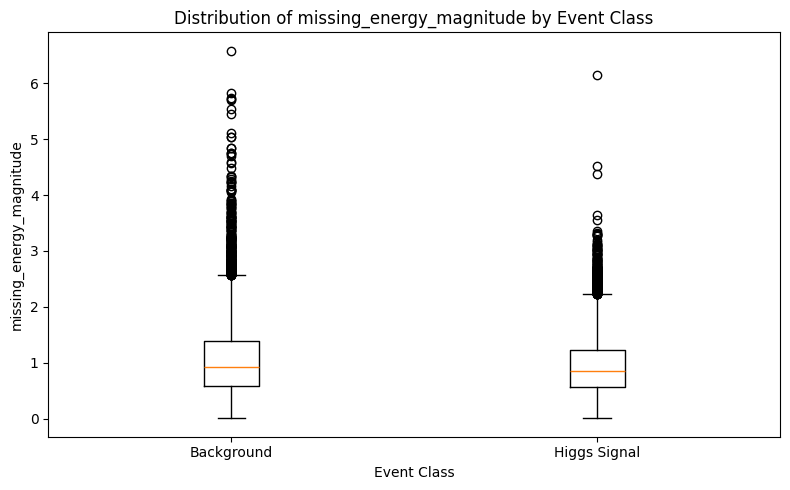

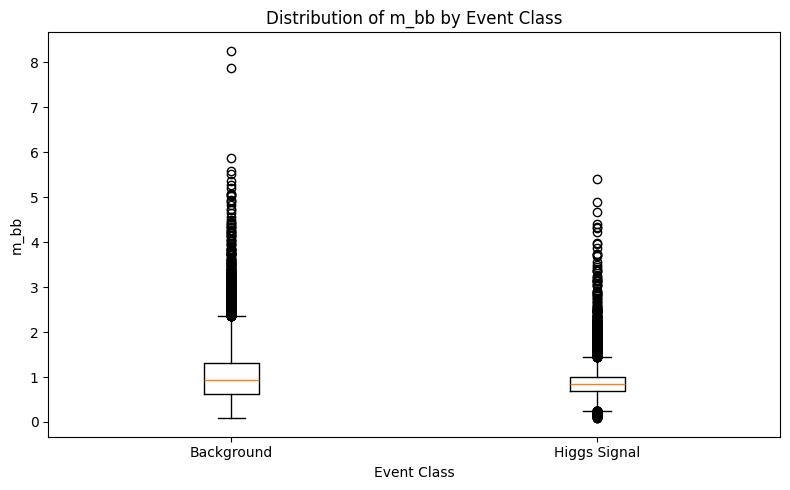

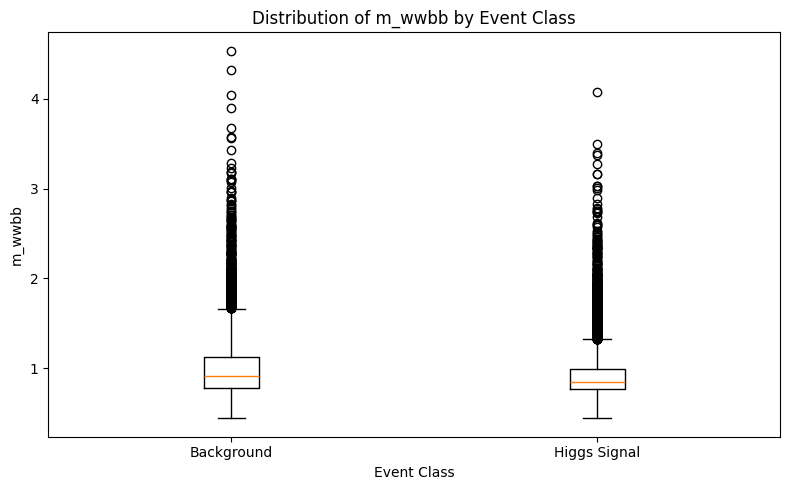

In [42]:
features_box = [
    "lepton_pt",
    "jet_1_pt",
    "missing_energy_magnitude",
    "m_bb",
    "m_wwbb"
]

for i in features_box:

    background = df[df["target"] == 0][i]
    signal = df[df["target"] == 1][i]

    plt.figure(figsize=(8, 5))

    plt.boxplot(
        [background, signal],
        tick_labels=["Background", "Higgs Signal"]
    )

    plt.xlabel("Event Class")
    plt.ylabel(i)
    plt.title(f"Distribution of {i} by Event Class")

    plt.tight_layout()
    plt.show()

## Task 3 — Part 5: Physical Interpretation of Feature Distributions

### 5.1 Transverse Momentum

Transverse momentum is an important observable in high-energy particle physics. It describes the component of a particle's momentum perpendicular to the collision beam axis.

\[
p_T=\sqrt{p_x^2+p_y^2}
\]

The features `lepton_pt` and `jet_1_pt` provide information about the kinematics of reconstructed particles and jets.

**Why might transverse momentum distributions differ between Signal and Background?**

Signal and background events originate from different physical processes. These processes can involve different intermediate particles, production mechanisms, and decay channels.

Consequently, the energies and momenta of the final-state particles may follow different statistical distributions.

For example, differences in the masses of intermediate particles can influence the momentum distributions of their decay products.

**Does a difference in transverse momentum guarantee accurate classification?**

No. Even when the mean or median values differ, signal and background distributions may overlap substantially.

Therefore, a single transverse momentum feature may provide useful classification information without being sufficient to distinguish the two classes reliably.

---

### 5.2 Missing Transverse Energy

Missing transverse energy, commonly denoted by \(E_T^{miss}\), is associated with an imbalance in the reconstructed transverse momenta of visible particles.

The missing transverse momentum vector can be expressed approximately as:

\[
\vec p_T^{\,miss}=-\sum_i\vec p_{T,i}^{\,visible}
\]

Its magnitude is commonly reported as missing transverse energy.

**Why do neutrinos contribute to missing transverse energy?**

Neutrinos interact only weakly with ordinary matter and generally escape particle detectors without producing directly measurable signals.

As a result, events containing neutrinos may exhibit an imbalance in the reconstructed transverse momentum.

For example, a W boson can decay through:

\[
W^\pm\rightarrow \ell^\pm+\nu
\]

where \(\ell\) represents a charged lepton.

**How can missing transverse energy help distinguish Signal from Background?**

Different physical processes may produce different neutrino kinematics and missing transverse momentum distributions.

Therefore, `missing_energy_magnitude` may contain useful information for classification.

However, missing transverse energy can also arise from detector resolution and reconstruction effects, and its distribution may overlap between signal and background events.

---

### 5.3 Invariant Mass Features

Invariant mass is one of the most important quantities in relativistic particle physics.

For a system with total energy \(E\) and momentum \(\vec p\), its invariant mass is:

\[
m^2c^4=E^2-p^2c^2
\]

In natural units, where \(c=1\):

\[
m^2=E^2-|\vec p|^2
\]

For multiple reconstructed particles:

\[
m^2=\left(\sum_i E_i\right)^2-\left|\sum_i\vec p_i\right|^2
\]

**Why are invariant mass distributions useful?**

When a particle decays into detectable products, the invariant mass reconstructed from those products may exhibit a concentration near the mass of the parent particle.

This makes invariant mass distributions useful for investigating particle resonances and decay processes.

**Physical interpretation of `m_bb`**

The feature `m_bb` represents a reconstructed invariant mass associated with a pair of bottom-quark jet candidates.

Such combinations may carry information about the underlying decay process.

**Physical interpretation of `m_wwbb`**

The feature `m_wwbb` represents a reconstructed invariant mass associated with a system containing two W-boson candidates and two bottom-quark candidates.

In the simulated HIGGS classification problem, this quantity is related to the kinematics of the signal process and can potentially help distinguish signal from background.

**Why might high-level features improve classification?**

High-level features combine several low-level observables using physically motivated relationships.

They may therefore make certain discriminative patterns easier for a machine learning algorithm to identify.

However, the usefulness of these features must be established experimentally through model evaluation.

---

### 5.4 Overlapping Signal and Background Distributions

Signal and background events can exhibit similar values for individual physical observables.

This occurs because different physical processes may produce final states with comparable kinematic properties.

Furthermore, particle interactions involve statistical fluctuations, and reconstructed observables are affected by detector and reconstruction uncertainties.

**Can overlapping distributions still be useful for classification?**

Yes.

Even when two classes have strongly overlapping distributions for individual features, they may exhibit different relationships between multiple features.

For example, two events may have similar transverse momentum values but differ in their reconstructed invariant masses or angular distributions.

Therefore, combining multiple observables may provide better classification performance than analyzing any single variable independently.

**Why might nonlinear machine learning algorithms be useful?**

Algorithms such as RBF SVM and Random Forest can represent nonlinear relationships between input features.

This allows them to identify complex decision boundaries that may not be captured by a simple linear classifier.

However, nonlinear models do not necessarily outperform linear models. Their performance must be evaluated using cross-validation and independent test data.

---

### 5.5 Final Discussion and Conclusions

The exploratory analysis of the HIGGS dataset provides an initial understanding of the physical observables used for signal-background classification.

Transverse momentum features describe the kinematic properties of reconstructed particles, while missing transverse energy provides information about momentum imbalance and potentially invisible particles.

High-level features, particularly reconstructed invariant masses such as `m_bb` and `m_wwbb`, are physically motivated candidates for distinguishing different particle production and decay processes.

Nevertheless, individual features may exhibit substantial overlap between signal and background events.

This motivates the use of machine learning algorithms capable of combining information from multiple physical observables.

An additional interesting aspect of the HIGGS dataset is the distinction between its 21 low-level and 7 high-level features. Comparing models trained with these different feature groups could help investigate the value of physics-motivated feature engineering.

Overall, exploratory data analysis establishes a foundation for understanding the dataset before model development.

The actual predictive importance of individual features will be investigated in subsequent tasks using cross-validation, model comparison, and feature importance analysis.

**The next step is Feature Correlation Analysis**, where we will examine statistical relationships between the 28 physical input features.

# Task 4 — Feature Correlation Analysis

## Objective

Investigate the statistical relationships between the 28 numerical features of the HIGGS dataset.

The goal is to identify strongly correlated physical observables, visualize the overall correlation structure, and understand the potential implications of feature correlation for machine learning classification.

---

## Part 1 — Pearson Correlation Matrix

Using the feature DataFrame `X`:

1. Calculate the Pearson correlation matrix for all 28 input features.
2. Store the resulting matrix in a variable named `corr_matrix`.
3. Display the correlation matrix.
4. Verify its dimensions.

### Theoretical Background

The Pearson correlation coefficient between two variables \(X\) and \(Y\) is defined as:

\[
r_{XY}=
\frac{\operatorname{Cov}(X,Y)}
{\sigma_X\sigma_Y}
\]

The coefficient takes values between -1 and 1:

- \(r=1\): Perfect positive linear correlation.
- \(r=-1\): Perfect negative linear correlation.
- \(r=0\): No linear correlation.

A correlation close to zero does not necessarily imply that two variables are statistically independent.

### Questions

1. What are the dimensions of the correlation matrix?
2. Why are all diagonal elements equal to 1?
3. Why is the correlation matrix symmetric?

---

## Part 2 — Correlation Heatmap

Visualize the correlation matrix using Seaborn.

### Instructions

1. Create a heatmap containing all 28 features.
2. Use a diverging color map, such as `coolwarm`.
3. Set the color scale from -1 to 1.
4. Include a color bar.
5. Add the title `HIGGS Dataset — Feature Correlation Matrix`.
6. Adjust the figure size to ensure that the feature names remain readable.

### Expected Outcome

A 28 × 28 heatmap illustrating positive, negative, and weak linear correlations between physical observables.

---

## Part 3 — Identify Strongly Correlated Features

Investigate which pairs of features exhibit the strongest linear correlations.

### Instructions

1. Exclude the diagonal elements of the correlation matrix.
2. Avoid counting the same feature pair twice.
3. Calculate the absolute correlation coefficients.
4. Identify and display feature pairs with:

\[
|r| > 0.7
\]

5. Sort the identified pairs by decreasing absolute correlation.

### Questions

1. Which feature pairs exhibit the strongest positive correlations?
2. Are there any strongly negatively correlated features?
3. Do any high-level invariant mass features correlate strongly with low-level features?
4. What could explain these correlations from a physical perspective?

**Note:** The threshold of 0.7 is an exploratory choice rather than a universal definition of strong correlation.

---

## Part 4 — Correlation with the Target

Investigate the relationship between individual physical features and the binary target variable.

### Instructions

1. Calculate the Pearson correlation between each numerical input feature and `target`.
2. Sort the features by their absolute correlation with the target.
3. Display the results in a table or horizontal bar chart.
4. Identify features exhibiting the strongest individual linear associations with the event class.

### Questions

1. Which features have the strongest correlation with the target?
2. Are these features low-level or high-level observables?
3. Does a weak correlation with the target necessarily mean that a feature is useless for classification?
4. Why might nonlinear relationships be missed by Pearson correlation?

---

## Part 5 — Physical Interpretation and Conclusions

Based on the correlation analysis, discuss:

1. Why physical observables derived from common reconstructed particles may be correlated.
2. How high-level invariant mass features can contain information related to multiple low-level observables.
3. Why strongly correlated features may introduce redundancy.
4. How feature correlation can affect Logistic Regression, KNN, SVM, and tree-based models.
5. Why correlated features should not automatically be removed without evaluating their effect on predictive performance.

### Expected Outcome

By completing this task, we should obtain:

- A 28 × 28 Pearson correlation matrix.
- A correlation heatmap.
- A ranked list of strongly correlated feature pairs.
- An analysis of individual feature associations with the target.
- A physical interpretation of the relationships between reconstructed observables.

**Important:** Do not remove features, perform scaling, or train machine learning models during this task. All analyses are exploratory.

In [44]:
corr_matrix = df.drop(columns=["target","class_name"]).corr()

In [45]:
corr_matrix

,lepton_pt,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet_1_pt,jet_1_eta,jet_1_phi,jet_1_btag,jet_2_pt,...,jet_4_eta,jet_4_phi,jet_4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
lepton_pt,1.000000,-0.002306,0.002909,-0.138358,0.000416,0.178144,-0.002054,-0.009648,-0.009911,0.010201,...,0.004669,-0.000793,0.002989,0.030243,0.025142,0.272446,0.118535,0.004274,0.098129,0.144804
lepton_eta,-0.002306,1.000000,-0.006796,0.003352,0.008567,-0.004947,0.273257,-0.004553,-0.007040,0.006236,...,0.175731,0.002777,0.005072,-0.005904,-0.006310,-0.002421,-0.002587,-0.000368,-0.001521,-0.001537
lepton_phi,0.002909,-0.006796,1.000000,0.006386,-0.057530,-0.001551,0.000799,-0.167640,0.001469,0.002476,...,-0.007258,-0.066931,-0.001215,0.011123,0.011081,-0.009699,0.005723,-0.002130,0.002169,0.006547
missing_energy_magnitude,-0.138358,0.003352,0.006386,1.000000,0.005807,0.193367,-0.010253,-0.001235,-0.023547,0.026671,...,0.001667,-0.001024,0.010128,0.031320,0.031878,0.170485,0.278740,0.033566,0.211953,0.300036
missing_energy_phi,0.000416,0.008567,-0.057530,0.005807,1.000000,-0.004597,-0.006034,-0.146133,-0.004036,0.007072,...,-0.010043,-0.030699,0.000711,0.001268,0.004260,-0.000720,0.000907,-0.006910,0.002468,0.003002
jet_1_pt,0.178144,-0.004947,-0.001551,0.193367,-0.004597,1.000000,-0.003670,-0.017728,-0.009877,0.478434,...,-0.006854,0.003335,-0.008888,0.177813,0.256071,0.025701,0.293858,0.344584,0.480477,0.446045
jet_1_eta,-0.002054,0.273257,0.000799,-0.010253,-0.006034,-0.003670,1.000000,-0.003612,0.000512,0.002097,...,0.183738,-0.003712,0.001985,-0.007312,-0.005894,-0.005120,-0.007903,0.000658,-0.006594,-0.005254
jet_1_phi,-0.009648,-0.004553,-0.167640,-0.001235,-0.146133,-0.017728,-0.003612,1.000000,-0.018166,-0.007843,...,-0.005510,-0.112741,-0.002773,-0.002409,-0.011634,0.012168,-0.014193,-0.015092,-0.017572,-0.008841
jet_1_btag,-0.009911,-0.007040,0.001469,-0.023547,-0.004036,-0.009877,0.000512,-0.018166,1.000000,-0.139712,...,-0.006762,0.003529,-0.240065,-0.117939,-0.066407,0.004807,0.133491,0.278947,0.113841,0.010329
jet_2_pt,0.010201,0.006236,0.002476,0.026671,0.007072,0.478434,0.002097,-0.007843,-0.139712,1.000000,...,0.003431,-0.002612,-0.025434,0.191323,0.261030,0.014172,0.214679,0.369923,0.429858,0.373457


In [46]:
corr_matrix.shape

(28, 28)

In [47]:
import seaborn as sns

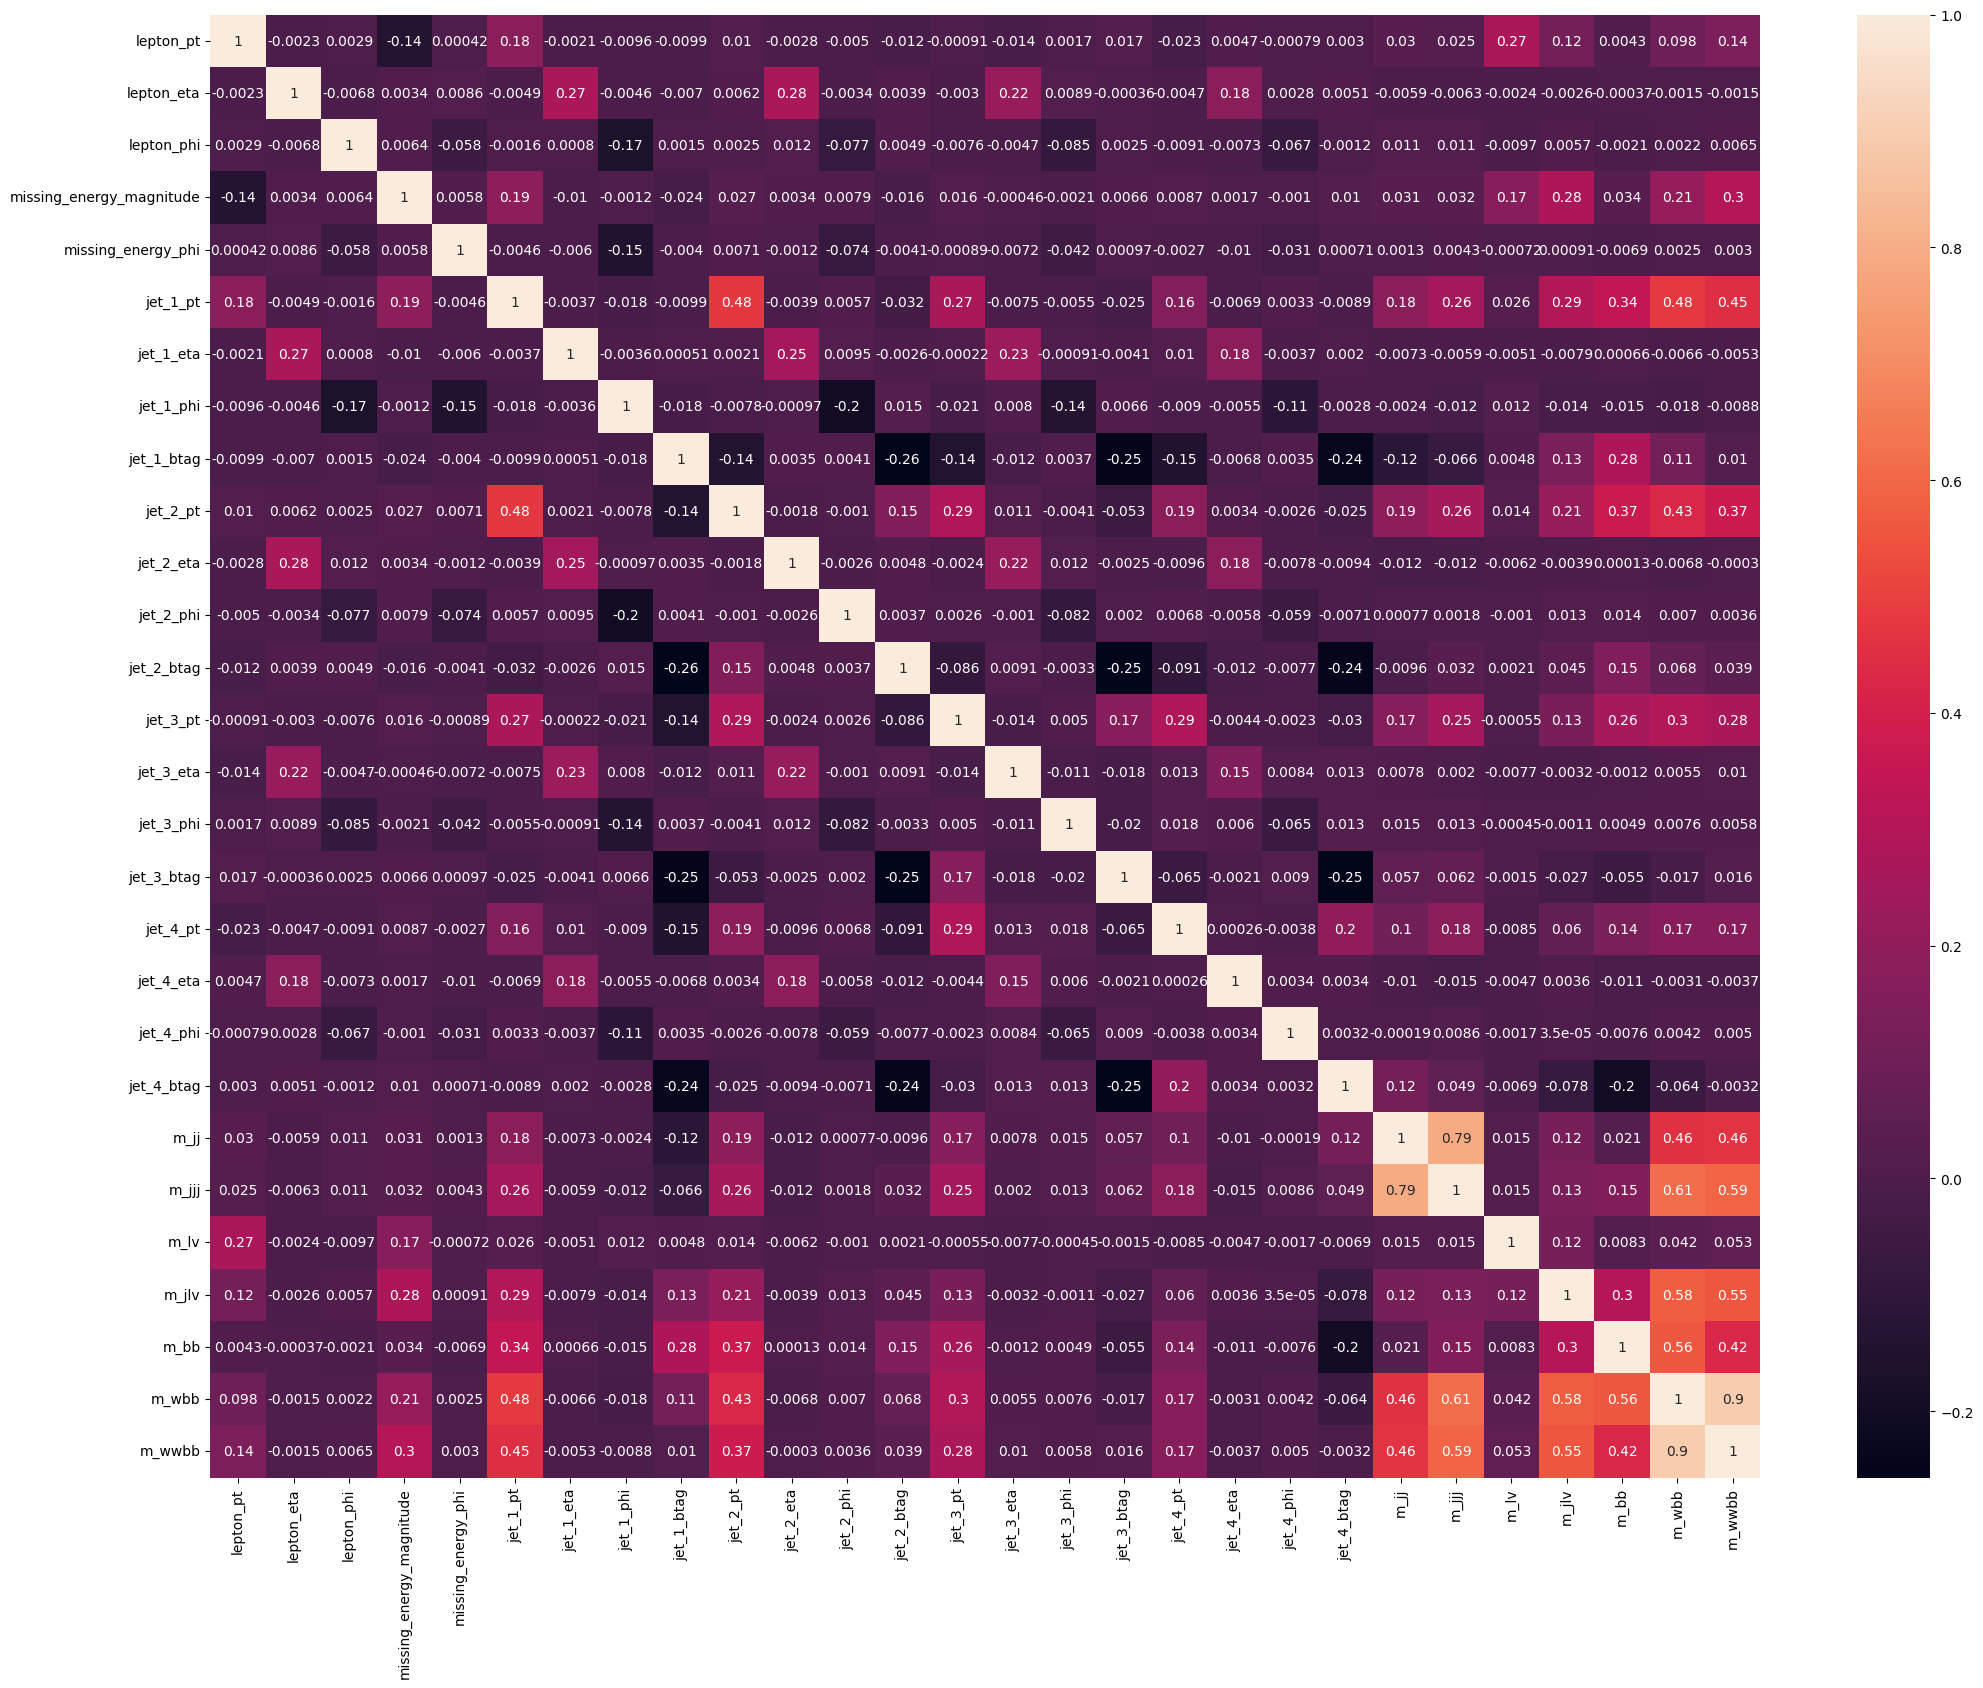

In [53]:
fig, ax = plt.subplots(figsize=(25, 19))
sns.heatmap(corr_matrix,annot=True)
plt.show()

In [58]:
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)


In [59]:
correlation_pairs = upper_triangle.stack()

In [60]:

strongest_correlations = correlation_pairs.reindex(
    correlation_pairs.abs().sort_values(ascending=False).index
)

strongest_correlations.head(10)

m_wbb     m_wwbb      0.895555
m_jj      m_jjj       0.793678
m_jjj     m_wbb       0.613319
          m_wwbb      0.588478
m_jlv     m_wbb       0.576254
m_bb      m_wbb       0.561838
m_jlv     m_wwbb      0.554394
jet_1_pt  m_wbb       0.480477
          jet_2_pt    0.478434
m_jj      m_wwbb      0.462079
dtype: float64

# Task 5 — Train-Test Split and Data Preparation

## Objective

Prepare the HIGGS dataset for supervised machine learning by dividing the observations into independent training and test sets.

The objective is to ensure that models are trained using one subset of the data and evaluated on previously unseen observations.

The test set must remain completely separate from model training, cross-validation, hyperparameter optimization, and model selection.

---

## Part 1 — Verify Features and Target

Using the existing variables `X` and `y`:

1. Verify that `X` contains all 28 numerical input features.
2. Verify that `y` contains the binary target variable.
3. Display the shapes of `X` and `y`.
4. Confirm that neither `target` nor `class_name` is included in `X`.

### Expected Dimensions

| Variable | Shape |
|---|---|
| `X` | (20000, 28) |
| `y` | (20000,) |

---

## Part 2 — Stratified Train-Test Split

Import `train_test_split` from `sklearn.model_selection`.

Split the dataset using:

- `test_size=0.20`
- `random_state=42`
- `stratify=y`

Store the resulting datasets in the following variables:

- `X_train`
- `X_test`
- `y_train`
- `y_test`

### Expected Dimensions

| Dataset | Expected Shape |
|---|---|
| `X_train` | (16000, 28) |
| `X_test` | (4000, 28) |
| `y_train` | (16000,) |
| `y_test` | (4000,) |

---

## Part 3 — Verify Class Distribution

Calculate the class distribution separately for the training and test sets.

### Instructions

1. Count the number of Background and Higgs Signal events in `y_train`.
2. Count the number of Background and Higgs Signal events in `y_test`.
3. Calculate the corresponding class percentages.
4. Compare the results with the original dataset distribution.

### Questions

1. Are the class proportions approximately preserved?
2. What is the purpose of stratified sampling?
3. Why is stratification useful in classification problems involving unequal class frequencies?

---

## Part 4 — Data Leakage Prevention

Explain why the test set must remain separate from all model development activities.

Consider the following questions:

1. Why should the test set not be used during hyperparameter optimization?
2. What happens if feature scaling is fitted using the complete dataset before splitting?
3. Why should preprocessing transformations be fitted exclusively on the training data?
4. How do scikit-learn Pipelines help prevent data leakage during cross-validation?

### Important

Do not apply feature scaling yet.

Scaling will be incorporated into the model Pipelines in a subsequent task.

---

## Part 5 — Final Verification

Verify that:

- The feature count is identical in the training and test sets.
- The target distributions are approximately preserved.
- Training and test observations are separated.
- The original DataFrame remains unchanged.
- No preprocessing transformation has been fitted using test data.

### Expected Outcome

At the end of this task, we should have four datasets ready for model development:

- `X_train`: Training features
- `X_test`: Test features
- `y_train`: Training labels
- `y_test`: Test labels

The training set will be used for cross-validation and model optimization.

The test set will be reserved for the final independent evaluation of the selected classifier.

In [65]:
X.shape[1]

28

In [66]:
y.unique()

array([1., 0.])

In [67]:
X.shape

(20000, 28)

In [68]:
y.shape

(20000,)

In [69]:
X.head()

,lepton_pt,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet_1_pt,jet_1_eta,jet_1_phi,jet_1_btag,jet_2_pt,...,jet_4_eta,jet_4_phi,jet_4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,0.869293,-0.635082,0.225690,0.327470,-0.689993,0.754202,-0.248573,-1.092064,0.000000,1.374992,...,-0.010455,-0.045767,3.101961,1.353760,0.979563,0.978076,0.920005,0.721657,0.988751,0.876678
1,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,0.812581,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
2,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,0.851737,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
3,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,2.423265,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
4,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,0.800872,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487


In [91]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [92]:
X_train.shape

(16000, 28)

In [93]:
X_test.shape

(4000, 28)

In [94]:
y_train.shape

(16000,)

In [95]:
y_test.shape

(4000,)

In [96]:
y_train.value_counts(normalize=True)*100

,proportion
target,
1.0,52.2875
0.0,47.7125


In [98]:
y_test.value_counts(normalize=True)*100

,proportion
target,
1.0,52.275
0.0,47.725


## Part 4 — Data Leakage Prevention

### Objective

Understand how to prevent data leakage during preprocessing, model training, cross-validation, and hyperparameter optimization.

### 1. Why should the test set remain completely separate during training and hyperparameter optimization?

The test set is intended to simulate previously unseen observations.

If test data are used during model training or hyperparameter optimization, information about the evaluation data may influence the model development process.

Consequently, the resulting test performance could be overly optimistic and might not accurately represent the model's ability to generalize to new collision events.

Therefore, the test set must remain unused until the final model and its hyperparameters have been selected.

### 2. What could happen if StandardScaler were fitted on the complete dataset before splitting?

StandardScaler transforms numerical features according to:

\[
z = \frac{x-\mu}{\sigma}
\]

where:

- \(\mu\) is the mean of the feature.
- \(\sigma\) is its standard deviation.
- \(x\) is the original feature value.

If StandardScaler is fitted on the complete dataset, both training and test observations contribute to the estimated means and standard deviations.

This introduces information from the test set into preprocessing, resulting in data leakage.

Although no target labels are directly used, the feature distributions of the test set still influence the transformation.

### 3. Why should preprocessing transformations be fitted only on the training data?

Preprocessing transformations often estimate parameters from the available observations.

Examples include:

- Feature means and standard deviations.
- Missing-value imputation statistics.
- Principal component directions.
- Feature selection criteria.

These parameters should be estimated exclusively from training data.

Once fitted, the transformations can be applied to validation and test observations without recalculating their parameters.

This ensures that evaluation data do not influence the preprocessing procedure.

### 4. How do scikit-learn Pipelines prevent data leakage during cross-validation?

A scikit-learn Pipeline combines preprocessing operations and a machine learning estimator into a single object.

For example, a classification pipeline may contain:

1. StandardScaler
2. LogisticRegression

During cross-validation, the Pipeline is fitted separately within each training fold.

The scaler estimates its parameters using only the training portion of that fold.

The validation portion is transformed using the previously fitted scaler and is then used to evaluate the classifier.

This procedure prevents validation data from influencing the preprocessing statistics.

### Conclusion

Preventing data leakage is essential for obtaining reliable estimates of machine learning performance.

In this project, preprocessing will be incorporated into scikit-learn Pipelines, and all model selection procedures will be performed exclusively on the training set.

The held-out test set will be used only for the final independent evaluation of the selected classifier.

# Task 6 — Feature Scaling and Preprocessing Strategy

## Objective

Investigate the importance of feature scaling in machine learning and determine the appropriate preprocessing strategy for each classification algorithm.

The HIGGS dataset contains 28 numerical features representing different physical observables, including transverse momenta, pseudorapidities, azimuthal angles, b-tagging information, and reconstructed invariant masses.

These features may exhibit different numerical ranges and statistical distributions.

The goal is to understand how feature scaling affects machine learning algorithms and prepare a suitable preprocessing strategy while preventing data leakage.

---

## Part 1 — Examine Feature Scales

Using `X_train`:

1. Calculate the mean and standard deviation of each numerical feature.
2. Calculate the minimum and maximum values.
3. Create a summary DataFrame containing these statistics.
4. Identify features with substantially different numerical ranges.

### Questions

1. Do all 28 features have similar numerical scales?
2. Which features exhibit the highest variability?
3. Why can features with large numerical ranges dominate distance calculations?

---

## Part 2 — Understand StandardScaler

Investigate the StandardScaler transformation:

\[
z=\frac{x-\mu}{\sigma}
\]

where:

- \(x\) is the original feature value.
- \(\mu\) is the feature mean calculated from the training data.
- \(\sigma\) is the feature standard deviation calculated from the training data.

### Questions

1. What is the approximate mean of a standardized feature?
2. What is its approximate standard deviation?
3. Does StandardScaler transform a skewed distribution into a normal distribution?
4. Why must the scaler be fitted only on training observations?

---

## Part 3 — Identify Which Models Require Scaling

Consider the seven classification algorithms used in this project:

1. Logistic Regression
2. K-Nearest Neighbors
3. Gaussian Naive Bayes
4. Linear SVM
5. RBF SVM
6. Decision Tree
7. Random Forest

### Instructions

Classify the algorithms into two groups:

- Models for which feature scaling is recommended.
- Models that generally do not require feature scaling.

Explain the reasoning behind your choices.

### Questions

1. Why is scaling important for KNN?
2. Why does scaling affect SVM classifiers?
3. Why are Decision Trees generally insensitive to feature scaling?
4. Why is scaling usually unnecessary for Gaussian Naive Bayes?

---

## Part 4 — Prevent Data Leakage with Pipelines

Investigate how scikit-learn Pipelines combine preprocessing and classification.

### Instructions

1. Import `StandardScaler` from `sklearn.preprocessing`.
2. Import `Pipeline` from `sklearn.pipeline`.
3. Examine the general structure of a pipeline containing:
   - `StandardScaler`
   - A classification estimator
4. Explain how preprocessing is performed independently within cross-validation folds.

### Questions

1. What happens when `.fit()` is called on a Pipeline?
2. What happens when `.predict()` is called?
3. Why is a Pipeline preferable to scaling the complete dataset before cross-validation?

**Important:** Do not fit the scaler or train any classifiers yet.

---

## Part 5 — Define the Preprocessing Strategy

Create a table specifying whether each classifier will use StandardScaler.

For each model, provide a short explanation of the preprocessing choice.

### Expected Outcome

A clear preprocessing plan for all seven classifiers, ready for implementation with scikit-learn Pipelines in the next task.

### Important Notes

- Use only `X_train` for examining feature scales.
- Do not fit preprocessing transformations on `X_test`.
- Do not perform model training or hyperparameter tuning.
- Preserve the original physical features without modifying the source dataset.

In [104]:
X_train.describe().drop(["25%", "50%", "75%"])

,lepton_pt,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet_1_pt,jet_1_eta,jet_1_phi,jet_1_btag,jet_2_pt,...,jet_4_eta,jet_4_phi,jet_4_btag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
count,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,...,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000
mean,0.996364,-0.006336,0.005808,0.990834,-0.006709,0.987797,-0.001116,-0.007854,1.000294,0.989804,...,-0.004254,-0.006466,0.989235,1.033618,1.023976,1.050173,1.012806,0.974804,1.032991,0.957728
std,0.573839,1.006044,1.004793,0.591981,1.005070,0.467539,1.010526,1.013899,1.026983,0.491138,...,1.009876,1.005970,1.393561,0.662832,0.378427,0.162501,0.398153,0.528306,0.362871,0.308135
min,0.274880,-2.425236,-1.742508,0.003158,-1.743094,0.159488,-2.960813,-1.741237,0.000000,0.188981,...,-2.496432,-1.742691,0.000000,0.146606,0.342015,0.266788,0.428113,0.093394,0.388779,0.441184
max,7.000281,2.429998,1.743236,5.824007,1.743052,4.489486,2.958781,1.741454,2.173076,7.627234,...,2.495511,1.742817,3.101961,16.131908,8.940148,3.682260,6.583121,7.859794,6.401313,4.535003


## Task 6 — Part 2: Understanding StandardScaler

### Objective

Understand how StandardScaler transforms numerical features and why standardization is important for certain machine learning algorithms.

### 1. What Is StandardScaler?

StandardScaler is a preprocessing technique that transforms numerical features by subtracting their mean and dividing by their standard deviation.

The transformation is defined as:

\[
z = \frac{x-\mu}{\sigma}
\]

where:

- \(x\): Original feature value.
- \(\mu\): Mean of the feature in the training data.
- \(\sigma\): Standard deviation of the feature in the training data.
- \(z\): Standardized feature value.

### 2. What Is the Mean of a Standardized Feature?

After applying StandardScaler, the transformed training feature has a mean approximately equal to zero.

\[
\mu_z \approx 0
\]

This occurs because the original mean is subtracted from every observation.

### 3. What Is the Standard Deviation of a Standardized Feature?

For a feature with nonzero variance, its transformed training values have a population standard deviation approximately equal to one.

\[
\sigma_z \approx 1
\]

This allows features with different numerical scales to become more comparable.

### 4. Does StandardScaler Produce a Normal Distribution?

No.

StandardScaler changes the location and scale of a distribution, but it does not change its overall shape.

For example, a strongly right-skewed feature will generally remain right-skewed after standardization.

Standardization does not guarantee that the transformed values follow a Gaussian distribution.

### 5. Why Must StandardScaler Be Fitted Only on Training Data?

StandardScaler estimates the mean and standard deviation from the data supplied to its `fit()` method.

If the scaler is fitted using the entire dataset, information from the test set influences the preprocessing transformation.

This causes data leakage and may lead to overly optimistic estimates of model performance.

Therefore, the scaler must be fitted exclusively on training observations.

During cross-validation, it must be fitted independently within each training fold.

### Example

Consider a feature with:

\[
\mu=10,\qquad \sigma=2
\]

For an observation with \(x=14\):

\[
z=\frac{14-10}{2}=\boxed{2}
\]

The standardized value is 2, meaning that the original observation is two standard deviations above the feature mean.

### Conclusion

StandardScaler is an important preprocessing technique for algorithms sensitive to feature magnitudes or distances.

It helps place numerical features on comparable scales and can improve numerical optimization.

In this project, standardization will be incorporated into scikit-learn Pipelines to prevent data leakage during training and cross-validation.

## Task 6 — Part 3: Feature Scaling Requirements

### Objective

Determine which classification algorithms benefit from feature scaling and explain the mathematical reasons behind each preprocessing choice.

### Scaling Strategy

| Classification Model | StandardScaler | Reason |
|---|---|---|
| Logistic Regression | Yes | Improves optimization and makes regularization more consistent across features. |
| K-Nearest Neighbors | Yes | Uses distances between observations and is sensitive to feature scales. |
| Gaussian Naive Bayes | Not required | Models the distribution of each numerical feature separately. |
| Linear SVM | Yes | Scaling affects margin optimization and regularization. |
| RBF SVM | Yes | The RBF kernel depends on distances between observations. |
| Decision Tree | Not required | Splits observations using feature thresholds. |
| Random Forest | Not required | Consists of decision trees and is generally insensitive to feature scaling. |

### 1. Why Is Scaling Important for KNN?

K-Nearest Neighbors uses distances between observations to identify neighboring samples.

For Euclidean distance:

\[
d(\mathbf{x},\mathbf{y})
=
\sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
\]

Features with larger numerical scales can dominate the distance calculation.

Standardization helps ensure that differences in measurement scale do not disproportionately influence the classification.

### 2. Why Does Scaling Affect SVM Classifiers?

Support Vector Machines construct decision boundaries using margin-based optimization.

In Linear SVM, scaling affects the geometry of the input space and the effect of regularization.

For an RBF SVM, the kernel is:

\[
K(\mathbf{x},\mathbf{y})
=
\exp\left(-\gamma\|\mathbf{x}-\mathbf{y}\|^2\right)
\]

Because the RBF kernel depends on squared Euclidean distances, large-scale features may dominate the similarity calculation.

Feature scaling helps balance their influence.

### 3. Why Are Decision Trees Generally Insensitive to Feature Scaling?

Decision Trees classify observations by applying threshold-based rules to individual features.

For example:

`lepton_pt <= 1.5`

A positive linear transformation changes the numerical threshold but preserves the ordering of observations.

As a result, the same partition can generally be obtained without standardization.

Random Forests inherit this property because they combine multiple decision trees.

### 4. Why Is Scaling Usually Unnecessary for Gaussian Naive Bayes?

Gaussian Naive Bayes estimates the mean and variance of each feature separately within each class.

When a feature is transformed linearly, its estimated mean and variance change accordingly.

Under the Gaussian model, this generally preserves the resulting classification decisions.

Small numerical differences may arise from implementation details such as variance smoothing.

### Conclusion

The following classifiers will use StandardScaler:

- Logistic Regression
- K-Nearest Neighbors
- Linear SVM
- RBF SVM

The following classifiers will initially be used without feature scaling:

- Gaussian Naive Bayes
- Decision Tree
- Random Forest

This preprocessing strategy will be implemented using scikit-learn Pipelines to ensure consistent and leakage-free model evaluation.

In [105]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [106]:
model_logistic_regression = LogisticRegression(random_state=42)
model_knn = KNeighborsClassifier()
model_gaussian_naive_bayes = GaussianNB()
model_linear_svm = SVC(kernel="linear", random_state=42)
model_rbf_svm = SVC(kernel="rbf", random_state=42)
model_decision_tree = DecisionTreeClassifier(random_state=42)
model_random_forest = RandomForestClassifier(random_state=42)

In [107]:

pipe_logistic_regression = Pipeline([
    ("scaler", StandardScaler()),
    ("model", model_logistic_regression)
])

pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", model_knn)
])
pipe_gaussian_naive_bayes = Pipeline([
    ("model", model_gaussian_naive_bayes)
])
pipe_linear_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", model_linear_svm)
])
pipe_rbf_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", model_rbf_svm)
])
pipe_decision_tree = Pipeline([
    ("model", model_decision_tree)
])
pipe_random_forest = Pipeline([
    ("model", model_random_forest)
])


In [109]:
models = {
    "Logistic Regression": pipe_logistic_regression,
    "KNN": pipe_knn,
    "Gaussian Naive Bayes": pipe_gaussian_naive_bayes,
    "Linear SVM": pipe_linear_svm,
    "RBF SVM": pipe_rbf_svm,
    "Decision Tree": pipe_decision_tree,
    "Random Forest": pipe_random_forest
}

## Task 6 — Part 5: Final Preprocessing Strategy

### Objective

Define and implement the preprocessing strategy for seven machine learning classification algorithms.

### Implementation

Seven classification estimators were initialized and incorporated into scikit-learn Pipelines.

StandardScaler was included for Logistic Regression, K-Nearest Neighbors, Linear SVM, and RBF SVM.

Gaussian Naive Bayes, Decision Tree, and Random Forest were configured without feature standardization.

All seven pipelines were organized into a Python dictionary named `models`, allowing consistent access to each classifier during training and evaluation.

### Data Leakage Prevention

In the pipelines containing StandardScaler, feature standardization will be fitted exclusively on the corresponding training observations.

During cross-validation, the scaler and classifier will be fitted independently within each training fold.

This prevents validation observations from influencing preprocessing statistics.

### Conclusion

The preprocessing strategy and classification pipelines have been successfully configured.

All seven models are ready for training and cross-validation using the HIGGS training dataset.

No test-set observations have been used during preprocessing or model configuration.

In [110]:
for name, pipeline in models.items():
    print(name)
    print(pipeline)
    print("-" * 50)

Logistic Regression
Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(random_state=42))])
--------------------------------------------------
KNN
Pipeline(steps=[('scaler', StandardScaler()),
                ('model', KNeighborsClassifier())])
--------------------------------------------------
Gaussian Naive Bayes
Pipeline(steps=[('model', GaussianNB())])
--------------------------------------------------
Linear SVM
Pipeline(steps=[('scaler', StandardScaler()),
                ('model', SVC(kernel='linear', random_state=42))])
--------------------------------------------------
RBF SVM
Pipeline(steps=[('scaler', StandardScaler()), ('model', SVC(random_state=42))])
--------------------------------------------------
Decision Tree
Pipeline(steps=[('model', DecisionTreeClassifier(random_state=42))])
--------------------------------------------------
Random Forest
Pipeline(steps=[('model', RandomForestClassifier(random_state=42))])
--------------------

# Task 7 — Initial Model Training

## Objective

Train seven machine learning classification models on the HIGGS training dataset using the previously configured scikit-learn Pipelines.

The objective is to establish an initial set of trained classifiers before evaluating their predictive performance through cross-validation.

## Part 1 — Train All Classifiers

Using the existing `models` dictionary:

1. Iterate over all seven classification pipelines using a `for` loop.
2. Call the `.fit()` method for each pipeline.
3. Use `X_train` as the input feature matrix.
4. Use `y_train` as the target vector.
5. Print a confirmation message after each model has been successfully trained.

The models are:

- Logistic Regression
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Linear SVM
- RBF SVM
- Decision Tree
- Random Forest

## Part 2 — Understand the Training Process

Answer the following questions:

1. What happens when `.fit(X_train, y_train)` is called?
2. How does the training process differ between Logistic Regression and KNN?
3. What is the role of StandardScaler inside the classification pipelines?
4. Why do Decision Trees and Random Forests not require feature standardization?
5. Why should the test set remain unused during model training?

## Part 3 — Verify Training Completion

After training all seven models:

1. Confirm that every pipeline completed training successfully.
2. Check whether any warnings were produced.
3. Identify any models that require significantly more training time.
4. Explain why computational requirements differ among classification algorithms.

## Expected Outcome

Seven trained classification pipelines ready for model evaluation.

The trained models will be evaluated using Stratified K-Fold Cross-Validation in the next task.

## Important Notes

- Use only `X_train` and `y_train`.
- Do not use `X_test` or `y_test`.
- Do not calculate accuracy or F1-score yet.
- Do not perform hyperparameter tuning.
- Keep feature scaling inside the existing Pipelines.

In [114]:
for name, pipeline in models.items():
  pipeline.fit(X_train, y_train)
  print(f"{name} has been trained")

Logistic Regression has been trained
KNN has been trained
Gaussian Naive Bayes has been trained
Linear SVM has been trained
RBF SVM has been trained
Decision Tree has been trained
Random Forest has been trained


## Task 7 — Part 2: Understanding the Model Training Process

### Objective

Understand how different classification algorithms learn from the training dataset and how preprocessing is incorporated into model training.

### 1. What happens when `.fit(X_train, y_train)` is called?

The `.fit()` method trains a machine learning estimator using the supplied training features and target labels.

Depending on the algorithm, training may involve:

- Estimating model coefficients.
- Optimizing an objective function.
- Learning probability distributions.
- Constructing decision boundaries.
- Building decision trees.

When `.fit()` is called on a Pipeline, the preprocessing steps are fitted and applied before the final classifier is trained.

In this project, all seven classifiers are trained using 16,000 simulated collision events and 28 numerical features.

### 2. How does training differ between Logistic Regression and KNN?

**Logistic Regression**

Logistic Regression learns a set of coefficients that describe the relationship between input features and the probability of belonging to a particular class.

For binary classification, the model estimates:

\[
P(y=1|\mathbf{x})=
\frac{1}{1+e^{-(\mathbf{w}^T\mathbf{x}+b)}}
\]

During training, the coefficients and intercept are optimized by minimizing a regularized loss function.

**K-Nearest Neighbors**

KNN is an instance-based learning algorithm.

Unlike Logistic Regression, it does not learn an explicit global decision function during fitting.

Instead, it stores the training observations and their labels.

During prediction, it identifies the nearest training samples and assigns a class based on their labels.

Consequently, KNN typically requires relatively little fitting time, but prediction can be computationally expensive.

### 3. What is the role of StandardScaler inside the Pipelines?

StandardScaler standardizes numerical features using:

\[
z=\frac{x-\mu}{\sigma}
\]

It estimates the mean and standard deviation of each feature from the training data.

Standardization is particularly important for algorithms sensitive to feature scales, such as Logistic Regression, KNN, Linear SVM, and RBF SVM.

Using StandardScaler inside a Pipeline ensures that preprocessing is performed consistently and prevents validation data from influencing scaling statistics during cross-validation.

### 4. Why do Decision Trees and Random Forests not require standardization?

Decision Trees make predictions using threshold-based decisions on individual features.

Positive linear scaling changes the numerical values of the thresholds but preserves the ordering of observations.

Therefore, the resulting data partitions generally remain unchanged.

Random Forests combine multiple Decision Trees and are similarly insensitive to standard feature scaling.

### 5. Why should the test set remain unused during model training?

The test set is reserved for evaluating the final selected model on previously unseen observations.

Using the test set during training or model selection would introduce information from the evaluation data into model development.

This could lead to an overly optimistic estimate of generalization performance.

Therefore, only the training set is used for fitting, cross-validation, and hyperparameter optimization.

### Conclusion

Different classification algorithms use different learning mechanisms and have different computational requirements.

Scikit-learn Pipelines provide a consistent framework for integrating preprocessing with model training.

By training all classifiers on the same training dataset, we establish a common foundation for subsequent model comparison and evaluation.

# Task 8 — Stratified K-Fold Cross-Validation

## Objective

Evaluate and compare seven classification algorithms using Stratified K-Fold Cross-Validation on the HIGGS training dataset.

The objective is to estimate the predictive performance of each classifier while preserving the original signal-background class distribution across validation folds.

Two evaluation metrics will be considered:

- Classification Accuracy
- Macro F1-score

The held-out test set must remain unused throughout this task.

---

## Part 1 — Configure Cross-Validation

Import the following utilities from `sklearn.model_selection`:

- `StratifiedKFold`
- `cross_validate`

Create a StratifiedKFold object named `cv` using:

- `n_splits=5`
- `shuffle=True`
- `random_state=42`

### Questions

1. Why is cross-validation preferable to evaluating a classifier on a single training-validation split?
2. Why is stratification useful for binary classification?
3. How many times will each classifier be trained during 5-fold cross-validation?

---

## Part 2 — Evaluate All Classifiers

Using the existing `models` dictionary:

1. Iterate over the seven classification pipelines.
2. Apply `cross_validate()` to each pipeline.
3. Use only `X_train` and `y_train`.
4. Use the `cv` object created in Part 1.
5. Evaluate each model using both:
   - `accuracy`
   - `f1_macro`
6. Display a message when the evaluation of each classifier is completed.

### Important

All preprocessing operations must remain inside the existing scikit-learn Pipelines.

Do not use `X_test` or `y_test`.

---

## Part 3 — Collect Cross-Validation Results

For each classifier, calculate:

- Mean Accuracy
- Standard Deviation of Accuracy
- Mean Macro F1-score
- Standard Deviation of Macro F1-score
- Mean Fit Time

Store the results in a pandas DataFrame with the following columns:

- `Model`
- `Mean Accuracy`
- `Std Accuracy`
- `Mean F1-Macro`
- `Std F1-Macro`
- `Mean Fit Time (s)`

Sort the DataFrame by `Mean F1-Macro` in descending order.

### Expected Outcome

A ranked comparison of the seven classification algorithms based on cross-validation performance.

---

## Part 4 — Visualize Model Performance

Create a bar chart comparing the mean Macro F1-scores of the seven classifiers.

### Requirements

1. Place classifier names on the horizontal axis.
2. Display mean Macro F1-score on the vertical axis.
3. Sort the classifiers by their cross-validation performance.
4. Add error bars representing the standard deviation across folds.
5. Include an appropriate chart title and axis labels.

### Questions

1. Which classifier achieves the highest mean Macro F1-score?
2. Which classifier exhibits the greatest variability across folds?
3. Is there a substantial difference between the best and worst classifiers?

---

## Part 5 — Model Comparison and Interpretation

Analyze the cross-validation results and answer the following questions:

1. Which classification algorithm achieves the highest predictive performance?
2. Are Accuracy and Macro F1-score approximately equal for most classifiers?
3. How does the performance of linear models compare with nonlinear models?
4. Do more computationally expensive algorithms necessarily achieve better classification performance?
5. Which models appear most promising for subsequent hyperparameter optimization?
6. Why should the final model not be selected using the held-out test set?

### Expected Outcome

A systematic comparison of seven machine learning classifiers using reproducible cross-validation.

The results will be used to identify promising models for further optimization.

**Important:** Do not perform hyperparameter tuning or final test-set evaluation during this task.

In [115]:
from sklearn.model_selection import StratifiedKFold,cross_val_score

In [116]:
cv =StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [128]:
cv_results =[]
cv_results_f1 =[]
for name, pipeline in models.items():
  scores = cross_val_score(estimator = pipeline,X = X_train,y = y_train,cv=cv,scoring='accuracy')
  scores_f1 = cross_val_score(estimator = pipeline,X = X_train,y = y_train,cv=cv,scoring='f1_macro')
  print(f"{name}:{scores}")
  print(f"{name}:{scores_f1}")
  cv_results.append({"Model":name,"Mean Accuracy":scores.mean(),"Std Accuracy":scores.std(), 'Fold Scores':scores})
  cv_results_f1.append({"Model":name,"Mean F1-Macro":scores_f1.mean(),"Std F1-Macro":scores_f1.std(), 'Fold F1-Scores':scores_f1})


Logistic Regression:[0.635625  0.6409375 0.649375  0.6425    0.633125 ]
Logistic Regression:[0.62923805 0.63449021 0.64517868 0.63781365 0.62804417]
KNN:[0.58      0.6071875 0.5865625 0.5959375 0.5915625]
KNN:[0.57612402 0.60206687 0.58297014 0.59284243 0.58719902]
Gaussian Naive Bayes:[0.584375  0.599375  0.599375  0.6028125 0.580625 ]
Gaussian Naive Bayes:[0.54798112 0.56708038 0.56880822 0.57181414 0.54442822]
Linear SVM:[0.6365625 0.6421875 0.655     0.638125  0.6321875]
Linear SVM:[0.61942779 0.62593584 0.64190201 0.62304688 0.61855281]
RBF SVM:[0.6653125 0.67      0.6853125 0.6690625 0.6684375]
RBF SVM:[0.66039671 0.66432713 0.68125595 0.66493886 0.66555655]
Decision Tree:[0.6046875 0.6153125 0.6175    0.6234375 0.58     ]
Decision Tree:[0.6039616  0.61479756 0.61709556 0.62270498 0.57938863]
Random Forest:[0.6984375 0.6965625 0.7090625 0.708125  0.6878125]
Random Forest:[0.69735931 0.69565228 0.70818978 0.70765725 0.68718782]


In [123]:
results_df = pd.DataFrame(cv_results).sort_values(by="Mean Accuracy", ascending=False)
display(results_df)
results_df_f1 = pd.DataFrame(cv_results_f1).sort_values(by="Mean F1-Macro", ascending=False)
display(results_df_f1)

,Model,Mean Accuracy,Std Accuracy,Fold Scores
6,Random Forest,0.700000,0.007886,"[0.6984375, 0.6965625, 0.7090625, 0.708125, 0...."
4,RBF SVM,0.671625,0.007022,"[0.6653125, 0.67, 0.6853125, 0.6690625, 0.6684..."
3,Linear SVM,0.640813,0.007783,"[0.6365625, 0.6421875, 0.655, 0.638125, 0.6321..."
0,Logistic Regression,0.640313,0.005673,"[0.635625, 0.6409375, 0.649375, 0.6425, 0.633125]"
5,Decision Tree,0.608188,0.015342,"[0.6046875, 0.6153125, 0.6175, 0.6234375, 0.58]"
2,Gaussian Naive Bayes,0.593312,0.008996,"[0.584375, 0.599375, 0.599375, 0.6028125, 0.58..."
1,KNN,0.592250,0.009161,"[0.58, 0.6071875, 0.5865625, 0.5959375, 0.5915..."


,Model,Mean F1-Macro,Std F1-Macro,Fold F1-Scores
6,Random Forest,0.699209,0.007907,"[0.6973593129978001, 0.6956522803795531, 0.708..."
4,RBF SVM,0.667295,0.007209,"[0.660396709201305, 0.6643271284711627, 0.6812..."
0,Logistic Regression,0.634953,0.006219,"[0.6292380460272666, 0.6344902143522833, 0.645..."
3,Linear SVM,0.625773,0.008485,"[0.6194277938991257, 0.6259358367659131, 0.641..."
5,Decision Tree,0.607590,0.015357,"[0.6039615971892232, 0.6147975550518657, 0.617..."
1,KNN,0.588240,0.008809,"[0.5761240184168437, 0.602066870058668, 0.5829..."
2,Gaussian Naive Bayes,0.560022,0.011439,"[0.5479811239636277, 0.5670803801216615, 0.568..."


# Task 9 — Hyperparameter Optimization

## Objective

Optimize the Random Forest and RBF Support Vector Machine classifiers using randomized hyperparameter search and Stratified K-Fold Cross-Validation.

The goal is to identify configurations that improve classification performance while maintaining a reasonable computational cost.

Model optimization will be performed exclusively on the training set.

## Part 1 — Define Hyperparameter Search Spaces

### Random Forest

Create a dictionary named `param_dist_rf` containing:

| Hyperparameter | Candidate Values |
|---|---|
| `model__n_estimators` | [100, 200, 300] |
| `model__max_depth` | [None, 5, 10, 20] |
| `model__min_samples_split` | [2, 5, 10] |
| `model__min_samples_leaf` | [1, 2, 4] |
| `model__max_features` | ["sqrt", "log2"] |

### RBF SVM

Create a dictionary named `param_dist_svm` containing:

| Hyperparameter | Candidate Values |
|---|---|
| `model__C` | [0.1, 1, 10, 100] |
| `model__gamma` | ["scale", 0.001, 0.01, 0.1, 1] |

The prefix `model__` is required because both classifiers are contained inside scikit-learn Pipelines.

## Part 2 — Configure RandomizedSearchCV

Import `RandomizedSearchCV` from `sklearn.model_selection`.

Create two search objects:

- `random_search_rf` for the Random Forest Pipeline.
- `random_search_svm` for the RBF SVM Pipeline.

Use the following configuration:

- `n_iter=12`
- `scoring="f1_macro"`
- `cv=cv`
- `random_state=42`
- `n_jobs=-1`

For Random Forest, configure the underlying classifier to use `n_jobs=1` when parallelizing the search, to avoid unnecessary nested parallelism.

## Part 3 — Execute Hyperparameter Optimization

Fit both RandomizedSearchCV objects using:

- `X_train`
- `y_train`

Measure the total execution time for each search.

Do not use the test set.

## Part 4 — Examine Optimization Results

For each optimized model, display:

1. Best hyperparameters (`best_params_`).
2. Best mean CV Macro F1-score (`best_score_`).
3. Best estimator (`best_estimator_`).
4. Total search execution time.

Create a comparison DataFrame containing the optimization results for both models.

## Part 5 — Compare Baseline and Optimized Models

Compare each model's optimized mean CV Macro F1-score with its baseline cross-validation Macro F1-score from Task 8.

Answer the following questions:

1. Did hyperparameter optimization improve the observed cross-validation performance?
2. Which optimized classifier achieved the higher mean Macro F1-score?
3. Which search required more computational time?
4. Why can a larger hyperparameter search increase the risk of selection bias?
5. Why should the final test set remain unused during hyperparameter optimization?

## Expected Outcome

Two optimized classification pipelines and a comparative analysis of their cross-validation performance.

The results will be used for final model selection in Task 10.

**Important:** The best cross-validation score from hyperparameter search may be optimistic because multiple configurations were evaluated. Final predictive performance will be assessed on the held-out test set.

In [130]:
param_dist_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

In [125]:
param_dist_svm ={'model__C':[0.1,1,10,100],'model__gamma':["scale", 0.001, 0.01, 0.1, 1]}

In [126]:
from sklearn.model_selection import RandomizedSearchCV

In [131]:
# Configure the underlying random forest classifier inside the pipeline to use n_jobs=1
models['Random Forest'].set_params(model__n_jobs=1)

random_search_rf = RandomizedSearchCV(
    estimator=models['Random Forest'],
    param_distributions=param_dist_rf,
    n_iter=12,
    scoring='f1_macro',
    cv=cv,
    random_state=42,
    n_jobs=-1
)

random_search_svm = RandomizedSearchCV(
    estimator=models['RBF SVM'],
    param_distributions=param_dist_svm,
    n_iter=12,
    scoring='f1_macro',
    cv=cv,
    random_state=42,
    n_jobs=-1
)

In [132]:
random_search_rf.fit(X_train,y_train)
random_search_svm.fit(X_train,y_train)


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                             ('model', SVC(random_state=42))]),
                   n_iter=12, n_jobs=-1,
                   param_distributions={'model__C': [0.1, 1, 10, 100],
                                        'model__gamma': ['scale', 0.001, 0.01,
                                                         0.1, 1]},
                   random_state=42, scoring='f1_macro')

In [133]:
import pandas as pd

tuning_results = []

for name, search in {
    "Random Forest": random_search_rf,
    "RBF SVM": random_search_svm
}.items():

    tuning_results.append({
        "Model": name,
        "Best CV Macro F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    by="Best CV Macro F1",
    ascending=False
)

display(tuning_results_df)

,Model,Best CV Macro F1,Best Parameters
0,Random Forest,0.708069,"{'model__n_estimators': 300, 'model__min_sampl..."
1,RBF SVM,0.667295,"{'model__gamma': 'scale', 'model__C': 1}"


In [135]:
baseline_results = results_df_f1.set_index("Model")

for name, search in {
    "Random Forest": random_search_rf,
    "RBF SVM": random_search_svm
}.items():

    baseline = baseline_results.loc[name, "Mean F1-Macro"]
    tuned = search.best_score_

    print(f"\n{name}")
    print(f"Baseline Macro F1: {baseline:.4f}")
    print(f"Tuned Macro F1:    {tuned:.4f}")
    print(f"Difference:        {tuned - baseline:+.4f}")


Random Forest
Baseline Macro F1: 0.6992
Tuned Macro F1:    0.7081
Difference:        +0.0089

RBF SVM
Baseline Macro F1: 0.6673
Tuned Macro F1:    0.6673
Difference:        +0.0000


# Task 10 — Final Model Selection

## Objective

Select the most promising classification model based on cross-validation performance and prepare it for final evaluation on the held-out test set.

Two classification algorithms were optimized using RandomizedSearchCV:

- Random Forest
- RBF Support Vector Machine

The primary model selection metric is the mean cross-validation Macro F1-score.

---

## Part 1 — Compare Optimized Models

Use the results obtained from RandomizedSearchCV to compare the optimized Random Forest and RBF SVM classifiers.

Display:

1. The best mean cross-validation Macro F1-score.
2. The best hyperparameter combination.
3. The difference in performance between the two models.

### Questions

1. Which optimized model achieves the highest Macro F1-score?
2. How large is the performance difference?
3. Does the highest cross-validation score guarantee superior performance on unseen data?

---

## Part 2 — Select the Final Classifier

Select the model with the highest mean cross-validation Macro F1-score.

Retrieve the optimized pipeline from its fitted RandomizedSearchCV object using `best_estimator_`.

Store the selected model in a variable named:

`final_model`

Do not fit the model again.

---

## Part 3 — Examine the Selected Model

Display:

1. The selected model's pipeline.
2. The optimized hyperparameters.
3. The number of trees in the Random Forest.
4. The maximum tree depth.
5. The minimum number of samples required to split a node.

### Questions

1. What is the role of `n_estimators`?
2. How does `max_depth` influence model complexity?
3. Why can limiting tree depth help reduce overfitting?

---

## Part 4 — Scientific Interpretation

Discuss why Random Forest may be suitable for distinguishing Higgs-related signal events from background processes.

Consider:

- Nonlinear relationships between physical observables.
- Interactions between low-level kinematic features and reconstructed invariant masses.
- The ability of ensemble learning to reduce the instability of individual decision trees.
- Limitations of model selection based on a single cross-validation configuration.

---

## Expected Outcome

A selected and trained Random Forest classifier stored in `final_model`, ready for independent evaluation on the held-out test set.

**Important:** Do not use `X_test` or `y_test` during this task. The test set will be used for the first time in Task 11.

In [136]:


model_comparison = pd.DataFrame({
    "Model": ["Random Forest", "RBF SVM"],
    "Best CV Macro F1": [
        random_search_rf.best_score_,
        random_search_svm.best_score_
    ],
    "Best Parameters": [
        random_search_rf.best_params_,
        random_search_svm.best_params_
    ]
})

model_comparison = model_comparison.sort_values(
    by="Best CV Macro F1",
    ascending=False
)

display(model_comparison)

difference = (
    random_search_rf.best_score_
    - random_search_svm.best_score_
)

print(f"Performance difference: {difference:.4f}")
print(f"Difference in percentage points: {difference * 100:.2f}")

,Model,Best CV Macro F1,Best Parameters
0,Random Forest,0.708069,"{'model__n_estimators': 300, 'model__min_sampl..."
1,RBF SVM,0.667295,"{'model__gamma': 'scale', 'model__C': 1}"


Performance difference: 0.0408
Difference in percentage points: 4.08


In [137]:
# Select the optimized Random Forest
final_model = random_search_rf.best_estimator_

print("Selected Model:")
print(final_model)

Selected Model:
Pipeline(steps=[('model',
                 RandomForestClassifier(max_depth=20, min_samples_leaf=4,
                                        n_estimators=300, n_jobs=1,
                                        random_state=42))])


In [138]:
# Extract Random Forest from the Pipeline
rf = final_model.named_steps["model"]

print("Selected Classifier: Random Forest")

print("\nBest Hyperparameters:")
print(random_search_rf.best_params_)

print("\nModel Configuration:")
print("Number of trees:", rf.n_estimators)
print("Maximum depth:", rf.max_depth)
print("Minimum samples split:", rf.min_samples_split)
print("Minimum samples leaf:", rf.min_samples_leaf)
print("Maximum features:", rf.max_features)

print(f"\nBest CV Macro F1: {random_search_rf.best_score_:.4f}")

Selected Classifier: Random Forest

Best Hyperparameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 20}

Model Configuration:
Number of trees: 300
Maximum depth: 20
Minimum samples split: 2
Minimum samples leaf: 4
Maximum features: sqrt

Best CV Macro F1: 0.7081


## Task 10 — Final Model Selection

### Objective

Select the best-performing classification model based on cross-validation results and prepare it for independent test evaluation.

### Model Comparison

Two classification algorithms were optimized using RandomizedSearchCV:

- Random Forest
- RBF Support Vector Machine

Hyperparameter optimization was performed using 5-fold Stratified Cross-Validation, with Macro F1-score as the evaluation metric.

The optimized models achieved the following results:

| Model | Best CV Macro F1 |
|---|---:|
| Random Forest | 0.7081 |
| RBF SVM | 0.6673 |

Random Forest achieved the highest observed cross-validation Macro F1-score, outperforming RBF SVM by approximately 4.08 percentage points.

### Final Model Selection

Based on the cross-validation results, the optimized Random Forest classifier was selected as the final model.

The selected pipeline was retrieved using `random_search_rf.best_estimator_`.

The estimator was already refitted on the complete training dataset by RandomizedSearchCV.

Therefore, no additional model training was required.

### Scientific Interpretation

The HIGGS dataset contains physical observables describing simulated high-energy particle collision events.

These include transverse momenta, angular variables, b-tagging information, and reconstructed invariant masses.

The relationships between these physical observables and the signal-background target may be nonlinear and involve interactions between multiple features.

Random Forest is well suited to investigating such relationships because it combines multiple decision trees and can learn nonlinear decision boundaries without requiring feature standardization.

Additionally, ensemble learning can reduce the variance associated with individual decision trees, improving the stability of predictions.

### Limitations

Although Random Forest achieved the highest observed cross-validation performance, several limitations should be considered.

First, the hyperparameter search examined only a limited number of candidate configurations.

Second, the best cross-validation score may be optimistic because the same validation procedure was used to select hyperparameters.

Third, the selected dataset contains only 20,000 simulated events from a much larger dataset.

Therefore, the results may depend on the particular subset and cross-validation configuration.

### Conclusion

The optimized Random Forest was selected as the final classifier because it achieved the strongest observed cross-validation Macro F1-score among the models considered.

The selected model is ready for evaluation on the previously unseen test set.

The held-out test observations were not used during model training, hyperparameter optimization, or model selection.